# Clase 02 — Clustering: segmentos y atípicos de los clientes

> **Pregunta de negocio:** ¿Qué tipos de clientes tenemos y cuáles no encajan
> en ninguno?

En la clase 1 construiste una tabla con una fila por cliente: 5 852 clientes
de un comercio online británico, cada uno descrito por su recencia,
frecuencia, gasto, productos distintos y devoluciones a fecha 2011-12-10. La
directora de marketing la ha visto y vuelve con una petición:

> "Con 5 852 clientes no puedo diseñar 5 852 campañas. Necesito unos pocos
> grupos, cuatro o cinco, que pueda explicar a mi equipo y a los que pueda
> tratar de forma distinta. Y quiero saber qué clientes no encajan en ninguno,
> porque sospecho que ahí hay mayoristas, errores y casos raros."

La primera parte de la petición es una **segmentación**: dividir a los
clientes en grupos homogéneos por dentro y distintos entre sí. La segunda es
una **detección de atípicos**: encontrar a los clientes cuyo comportamiento
no se parece al de nadie. Podríamos segmentar con reglas escritas a mano
("gasto > 1 000 y recencia < 90 días = cliente activo de valor"), pero los
umbrales son arbitrarios y, con más de dos o tres variables, las reglas se
multiplican. En este notebook dejarás que los datos propongan los grupos, con
el primer algoritmo de *machine learning* del curso, y después usarás el
criterio de negocio para decidir qué hacer con ellos.

### Antes de empezar: qué necesitas

1. **Python 3 con Jupyter** y las librerías `pandas`, `numpy`, `matplotlib`,
   `scikit-learn`, `scipy` (se instala con scikit-learn) y `pyarrow` (sirve
   para leer los ficheros `.parquet`). Si te falta alguna, instálala desde
   una celda con `%pip install scikit-learn` (cambiando el nombre por el de
   la que falte) y reinicia el kernel.
2. **Dos ficheros de datos**, que te dará el profesor. Cópialos a mano en
   **la misma carpeta que este notebook**, sin cambiarles el nombre:

| Fichero | Tamaño | Para qué sirve |
| --- | --- | --- |
| `customers.parquet` | 0,2 MB | La tabla de cliente de la clase 1: el punto de partida |
| `customers_segments_referencia.parquet` | 0,2 MB | La tabla de segmentos de referencia: celdas de rescate y comprobar la tuya |

No necesitas tu tabla de la clase 1: `customers.parquet` es la de referencia.
La primera celda de código comprueba que los dos ficheros están en la
carpeta y, si falta alguno, te dice cuál.

### Qué vas a aprender y qué vas a entregar

Al terminar habrás preparado las variables de los clientes para medir
distancias, aplicado K-means y elegido el número de grupos con criterio,
aplicado DBSCAN para encontrar a los clientes que no encajan, dibujado un
mapa de los segmentos con PCA y convertido los grupos en segmentos con
nombre y acción.

Entregables (en la carpeta `salidas/`, que se crea sola):

- `customers_segments.parquet`: la tabla de cliente con su segmento y la
  marca de atípico;
- `fichas_segmento.csv`: una ficha por segmento;
- `catalogo_atipicos.csv`: los atípicos, con su motivo y su tratamiento.

### Índice

| Parte | Contenido |
| --- | --- |
| 0 | Aprender sin etiquetas y configuración |
| A | Demo guiada: cómo leer el código y el recorrido completo, del fichero al mapa |
| B1 | Distancia, transformación y escalado (ejercicios 1 y 2) |
| B2 | K-means y elección de K (ejercicios 3 y 4) |
| B3 | Perfilar los clusters (ejercicio 5) |
| B4 | DBSCAN (ejercicio 6) |
| B5 | El ruido como información (ejercicio 7) |
| B6 | Ver los segmentos: PCA (ejercicio 8) |
| B7 | De cluster a segmento (ejercicios 9 y 10) |
| C | Síntesis |
| Ampliación | Opcional (X1 y X2) |

### Cómo trabajar con este notebook

- Cada parte empieza con una **explicación** y un **ejemplo resuelto**:
  léelos y ejecuta sus celdas antes de pasar a los ejercicios. Todo lo que
  necesitas para resolverlos está en el notebook.
- Las celdas de ejercicio tienen huecos `COMPLETA` con un comentario
  `# TODO:` que dice qué falta. Si al ejecutar ves
  `NameError: name 'COMPLETA' is not defined`, te falta rellenar un hueco.
- Tras cada ejercicio de código hay una **celda de comprobación**: si
  imprime `✔ Correcto`, vas bien; si no, su mensaje te orienta.
- Las **celdas de rescate** cargan un resultado ya preparado para que puedas
  seguir si te has atascado o te has saltado un ejercicio: cambia
  `USAR_RESCATE = False` por `True` y ejecútala.
- Las celdas **Tu respuesta** son para escribir tus conclusiones.
- Si ves un `FileNotFoundError` al cargar datos, el notebook se ha abierto
  fuera de su carpeta o falta uno de sus ficheros: el mensaje dice en qué
  carpeta los está buscando.
- Algunos algoritmos usan números al azar. Fijamos siempre la semilla
  (`random_state=SEMILLA`) para que obtengas exactamente las mismas cifras
  que el texto.

## 0. Aprender sin etiquetas

En la mayoría de problemas de *machine learning* del curso habrá una
**respuesta conocida** en los datos: si una reseña es positiva (clase 4), si
un cliente abandonó (clase 6), cuánto gastó después (clase 7). El algoritmo
aprende a reproducir esa respuesta. A eso se le llama **aprendizaje
supervisado**, porque la respuesta, la **etiqueta**, actúa como un supervisor
que corrige al modelo.

Hoy no hay etiqueta. Nadie ha marcado a cada cliente como "mayorista" o
"particular ocasional": solo tenemos sus variables de comportamiento. El
**aprendizaje no supervisado** busca estructura en esas variables: grupos de
clientes parecidos entre sí (*clustering*), direcciones en las que los
clientes más varían (PCA) o puntos que no se parecen a ningún otro
(atípicos).

La consecuencia práctica es importante: **no hay una respuesta correcta con
la que comparar**. Solo podemos medir si los grupos son compactos y
separados, si son estables y, sobre todo, si son útiles. Un clustering no
descubre "los tipos de clientes que existen en el mundo": propone una forma
de dividirlos que depende de las variables elegidas, de su transformación y
del algoritmo. Otra elección daría otros grupos, igual de "correctos".

| Uso | Pregunta | Ejemplo en nuestro comercio |
| --- | --- | --- |
| Segmentar | ¿Qué tipos de clientes tenemos? | Grupos para adaptar comunicación, oferta y nivel de servicio |
| Resumir | ¿Cómo describo a 5 852 clientes en una diapositiva? | Cuatro fichas con tamaño, valor y comportamiento |
| Detectar lo inusual | ¿Quién no se parece a nadie? | Mayoristas, devoluciones masivas, errores de datos |

**El cierre de cada análisis**, como en la clase 1:

**métrica técnica → interpretación → decisión → limitación → guardrail**

Aquí no habrá una métrica de acierto (no hay etiquetas): las métricas
medirán la compacidad y la estabilidad de los grupos y cuántos clientes
quedan fuera. En las preguntas de interpretación bastará con los dos
primeros pasos: cita una cifra y di qué decisión permite tomar.

### Configuración

Importamos las librerías, comprobamos que los ficheros de la clase están en
esta carpeta, fijamos la semilla y un estilo sobrio para las figuras.

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow  # no se usa directamente: pandas la necesita para leer los .parquet
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from sklearn.cluster import DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_samples, silhouette_score
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

# Los ficheros de datos tienen que estar en la misma carpeta que este notebook.
FICHEROS_CLASE = ["customers.parquet", "customers_segments_referencia.parquet"]
faltan = []
for fichero in FICHEROS_CLASE:
    if not Path(fichero).exists():
        faltan.append(fichero)
if faltan:
    raise FileNotFoundError(f"Faltan estos ficheros en la carpeta {Path.cwd()}: {faltan}. "
                            "Cópialos a mano junto al notebook, sin cambiarles el nombre "
                            "(ver 'Antes de empezar'). Si ya están, abre el notebook "
                            "desde su propia carpeta.")

# Aquí se guardan tus entregables.
DIR_SALIDAS = Path("salidas")
DIR_SALIDAS.mkdir(exist_ok=True)

# Semilla de todo lo que usa números al azar: así todos obtenemos las mismas cifras.
SEMILLA = 42

pd.set_option("display.width", 100)
pd.set_option("display.max_columns", 12)
pd.set_option("display.float_format", "{:,.2f}".format)

AZUL, NARANJA, AQUA, AMARILLO, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#52514e"
COLORES = [AZUL, NARANJA, AQUA, AMARILLO]   # un color por cluster
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": GRIS,
    "xtick.color": GRIS,
    "ytick.color": GRIS,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "grid.linewidth": 0.8,
})
print("✔ Configuración lista")

✔ Configuración lista


## Parte A · Demo guiada

Empezamos por el destino: en unas pocas celdas iremos del fichero de
clientes a un mapa con los segmentos y los atípicos. El resto del notebook
justifica, paso a paso, cada decisión que la demo toma sin explicar. Antes,
unas piezas de Python que vas a ver a menudo.

### A.1 Cómo leer el código de este notebook

Cuatro piezas de Python que no se explicaron en la clase 1:

- Una **comprensión de lista**, `[f(x) for x in lista]`, es un bucle `for`
  con `append` escrito en una línea: aplica algo a cada elemento y devuelve
  la lista de resultados. Con `if` al final, solo se queda con los elementos
  que cumplen la condición.
- `zip` empareja dos listas elemento a elemento.
- `enumerate` recorre una lista dando además la posición (0, 1, 2...) de cada
  elemento.
- `", ".join(lista)` une una lista de textos con comas.

Y cuatro más que verás en las celdas dadas y en algún ejercicio:

- `def nombre(argumentos):` define una **función**: un bloque de código con
  nombre que recibe datos y devuelve un resultado con `return`. Se escribe
  una vez y se usa muchas.
- `assert condición, "mensaje"` no hace nada si la condición se cumple y se
  detiene con el mensaje si no: es lo que usan las celdas de comprobación.
- `tabla.iterrows()` recorre una tabla fila a fila y da, en cada vuelta, el
  nombre de la fila (su índice) y la fila.
- `.to_numpy()` convierte una columna o una fila de pandas en una matriz de
  NumPy, el formato con el que trabajan scikit-learn y las cuentas.

Con datos de juguete:

In [3]:
numeros = [1, 2, 3]
print([n * 10 for n in numeros])        # comprensión: aplica algo a cada elemento
print([n for n in numeros if n > 1])    # con filtro: solo los que cumplen la condición

dobles = []                             # lo mismo que la primera línea, con un bucle
for n in numeros:
    dobles.append(n * 10)
print(dobles)

print(dict(zip(["A", "B"], [0, 1])))    # zip empareja dos listas; dict las convierte en diccionario
for posicion, letra in enumerate(["x", "y"]):
    print(posicion, letra)              # enumerate da la posición y el elemento
print(", ".join(["A", "B", "C"]))       # join une textos con el separador indicado


def doble(x):
    '''Devuelve el doble de x.'''
    return 2 * x


print(doble(21))
assert doble(2) == 4, "doble no funciona"   # se cumple: no muestra nada

mini = pd.DataFrame({"compras": [2, 10]}, index=["A", "D"])
for nombre, fila in mini.iterrows():
    print(nombre, fila["compras"], fila.to_numpy())

[10, 20, 30]
[2, 3]
[10, 20, 30]
{'A': 0, 'B': 1}
0 x
1 y
A, B, C
42
A 2 [2]
D 10 [10]


### A.2 El recorrido en cinco pasos

| Paso | Pregunta que responde | Dónde se justifica |
| --- | --- | --- |
| 1. Preparar las variables | ¿Cómo medimos que dos clientes se parecen? | B1 |
| 2. K-means | ¿En qué grupos dividimos a los clientes? ¿Cuántos? | B2 y B3 |
| 3. DBSCAN | ¿Quién no se parece a nadie? | B4 y B5 |
| 4. PCA | ¿Cómo dibujamos clientes descritos por cuatro variables? | B6 |
| 5. De cluster a segmento | ¿Qué nombre y qué acción damos a cada grupo y a cada atípico? | B7 |

### A.3 Dos figuras que verás en la demo

- **El mapa PCA.** Cada punto es un cliente. Cada cliente tiene cuatro
  variables y no podemos dibujar cuatro dimensiones, así que PCA las resume
  en dos ejes que conservan la mayor parte de las diferencias entre clientes.
  El título del mapa dice qué porcentaje de esa información cabe en el
  dibujo. El color es el grupo de K-means y los círculos negros, los
  atípicos de DBSCAN. Cómo se construye, en B6.
- **El dendrograma.** Otra forma de agrupar, el *clustering jerárquico*:
  empieza con cada cliente solo y, paso a paso, une los dos grupos más
  parecidos hasta que queda uno. El árbol dibuja esas uniones: cuanto más
  alta es una unión, más distintos eran los grupos que se unieron. Cortar el
  árbol a una altura da un número de grupos.

### A.4 La demo: del fichero al mapa

Todas las variables de la demo llevan el sufijo `_demo` para no chocar con
las que crearás tú en el laboratorio.

**Paso 1.** Cargamos la tabla de la clase 1 y transformamos las cuatro
variables de comportamiento: logaritmo y después estandarización. ¿Por qué?
→ B1.

In [4]:
customers_demo = pd.read_parquet("customers.parquet")
VARIABLES = ["recency_days", "frequency", "monetary", "n_products"]
X_demo = StandardScaler().fit_transform(np.log1p(customers_demo[VARIABLES]))
print(customers_demo.shape, "->", X_demo.shape)

(5852, 11) -> (5852, 4)


**Paso 2.** K-means con cuatro grupos. ¿Por qué cuatro? → B2. ¿Quién está en
cada grupo? → B3.

In [ ]:
kmeans_demo = KMeans(n_clusters=4, n_init=10, random_state=SEMILLA).fit(X_demo)
# bincount cuenta cuántos clientes tienen la etiqueta 0, 1, 2 y 3.
print("Clientes por cluster:", np.bincount(kmeans_demo.labels_).tolist())

Clientes por cluster: [1235, 1511, 1267, 1839]


**Nota para el examen:** n_init para hacer 10 pruebas y quedarnos con la mejor. Cuanto menor la inercia mejor, son grupos más compactos.

**INERCIA:** La inercia mide la suma de las distancias al cuadrado de cada punto a su centroide asignado. Mide cómo de
compactos son los clústeres por dentro

**Paso 3.** DBSCAN marca como ruido (etiqueta −1) a los clientes que no se
parecen a nadie. ¿Por qué estos parámetros? → B4. ¿Quiénes son? → B5.

In [6]:
dbscan_demo = DBSCAN(eps=0.8, min_samples=8).fit(X_demo)
atipico_demo = dbscan_demo.labels_ == -1
print(f"Atípicos: {atipico_demo.sum()} ({atipico_demo.mean():.1%})")

Atípicos: 67 (1.1%)


**Paso 4.** PCA resume las cuatro variables en dos ejes, y dibujamos el mapa
(→ B6).

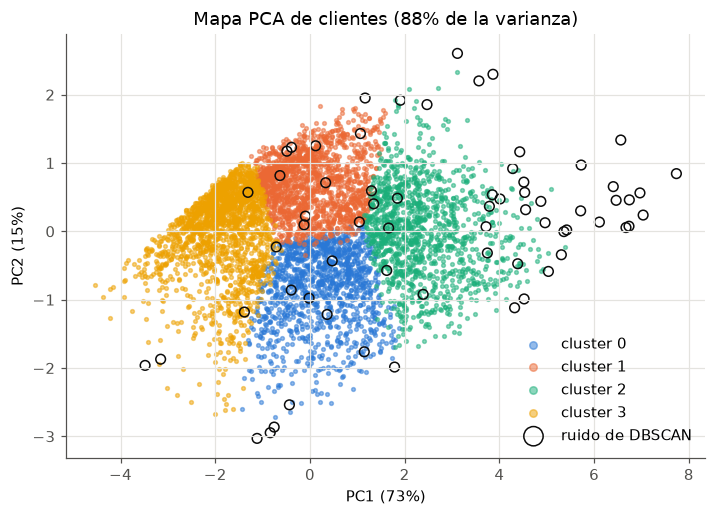

In [7]:
pca_demo = PCA(n_components=2, random_state=SEMILLA).fit(X_demo)
coords_demo = pca_demo.transform(X_demo)

# Código de la figura (no hace falta entenderlo para seguir la clase).
fig, ax = plt.subplots(figsize=(7.5, 5))
for k in range(4):
    mask = (kmeans_demo.labels_ == k) & ~atipico_demo
    ax.scatter(coords_demo[mask, 0], coords_demo[mask, 1], s=6, alpha=0.5, color=COLORES[k],
               label=f"cluster {k}")
ax.scatter(coords_demo[atipico_demo, 0], coords_demo[atipico_demo, 1], s=40, facecolors="none",
           edgecolors="#0b0b0b", linewidths=1, label="ruido de DBSCAN")
ratio = pca_demo.explained_variance_ratio_
ax.set(title=f"Mapa PCA de clientes ({ratio.sum():.0%} de la varianza)",
       xlabel=f"PC1 ({ratio[0]:.0%})", ylabel=f"PC2 ({ratio[1]:.0%})")
ax.legend(frameon=False, markerscale=2)
plt.show()

El mapa resume la segmentación de un vistazo: de izquierda a derecha crece la
intensidad de la relación con el comercio, los cuatro grupos son zonas
contiguas de una misma nube y la mayoría de los atípicos está en el borde
derecho. En B6 aprenderás a leerlo con cuidado (y cuándo engaña).

**Otra mirada al número de grupos.** El dendrograma de una muestra de 300 clientes (con
semilla fija, porque con los 5 852 sería lento de calcular y de leer). Usa el
criterio de **Ward**: en cada paso une los dos grupos cuya unión hace que
los grupos sean menos compactos lo mínimo posible.

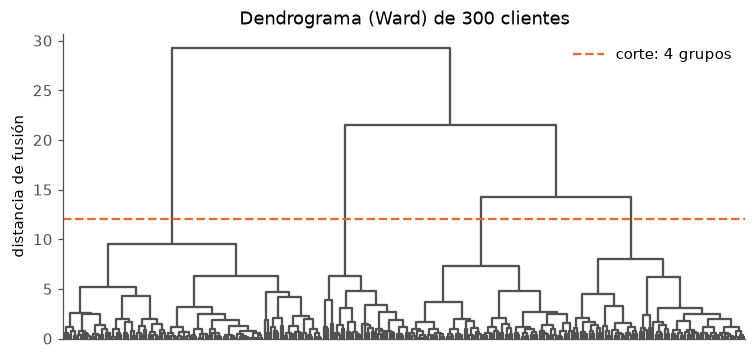

In [8]:
rng = np.random.default_rng(SEMILLA)
muestra_demo = rng.choice(len(X_demo), size=300, replace=False)   # 300 posiciones al azar
enlaces_demo = linkage(X_demo[muestra_demo], method="ward")       # todas las uniones de Ward

# Código de la figura (no hace falta entenderlo para seguir la clase).
fig, ax = plt.subplots(figsize=(8, 3.6))
dendrogram(enlaces_demo, no_labels=True, color_threshold=0, above_threshold_color=GRIS, ax=ax)
ax.axhline(12, color=NARANJA, linestyle="--", linewidth=1.5, label="corte: 4 grupos")
ax.set(title="Dendrograma (Ward) de 300 clientes", ylabel="distancia de fusión")
ax.legend(frameon=False)
ax.grid(False)
plt.show()

Las uniones más altas (hacia 29, 21 y 14) separan grupos muy distintos; por
debajo de 10 son mucho más bajas y parecidas entre sí. Un corte a la altura
12 deja cuatro ramas, lo que coincide con los cuatro grupos de K-means. El
dendrograma no demuestra que cuatro sea "lo correcto", pero es un buen
argumento visual para explicar la decisión a alguien que no conoce las
métricas de B2. (En la ampliación X2 cortarás el árbol y lo compararás con
K-means.)

**Paso 5.** Convertir los grupos y los atípicos en fichas con nombre y
acción, y en un catálogo con tratamiento, es el trabajo de B7. Ahora, a
justificar cada paso.

*Para saber más: capítulo de la clase 2, apartados 02.4.5 y 02.6.5.*

## Parte B · Laboratorio

### B1. Distancia, transformación y escalado

Para agrupar clientes parecidos hay que definir qué significa "parecido".
Lo más habitual es tratar a cada cliente como un **punto** en un espacio con
una dimensión por variable y medir la **distancia** entre puntos: cuanto más
cerca, más parecidos.

**Ejemplo resuelto: seis clientes.** Dos variables, número de compras y gasto
en libras. A la vista hay dos grupos: A, B y C compran poco y gastan poco; D,
E y F compran a menudo y gastan mucho.

In [9]:
seis = pd.DataFrame({
    "frequency": [2, 3, 1, 10, 12, 9],
    "monetary":  [150, 200, 100, 1200, 1500, 1000],
}, index=list("ABCDEF"))
seis

,frequency,monetary
A,2,150
B,3,200
C,1,100
D,10,1200
E,12,1500
F,9,1000


La **distancia euclídea** entre dos clientes $p$ y $q$ con variables
$x_1, \dots, x_m$ es la del teorema de Pitágoras:

$$
d(p, q) = \sqrt{\sum_{j=1}^{m} (p_j - q_j)^2}.
$$

Para A = (2, 150) y B = (3, 200): $\sqrt{(3-2)^2 + (200-150)^2} =
\sqrt{1 + 2\,500} = 50{,}01$. La función `distancia` hace esa cuenta; la
usarás en todo el notebook.

In [10]:
def distancia(p, q):
    '''Distancia euclídea: raíz de la suma de las diferencias al cuadrado.'''
    return np.sqrt(((p - q) ** 2).sum())

# seis.loc["A"] es la fila del cliente A: sus dos variables.
print(f"d(A, B) = {distancia(seis.loc['A'], seis.loc['B']):7.2f}")
print(f"d(A, C) = {distancia(seis.loc['A'], seis.loc['C']):7.2f}")
print(f"d(D, F) = {distancia(seis.loc['D'], seis.loc['F']):7.2f}")

d(A, B) =   50.01
d(A, C) =   50.01
d(D, F) =  200.00


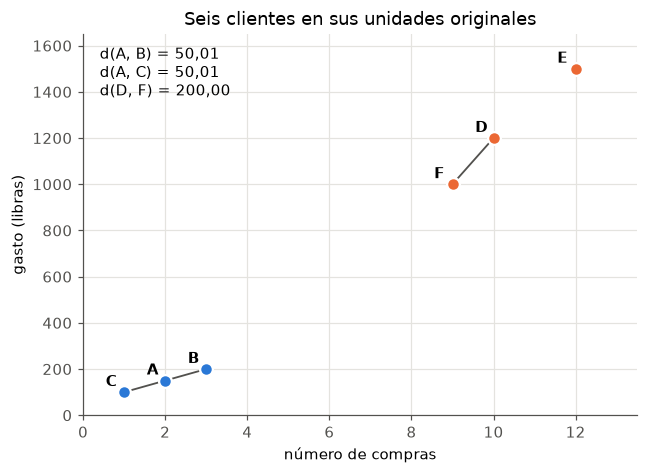

In [11]:
# Código de la figura (no hace falta entenderlo para seguir la clase).
GRUPO = {c: AZUL if c in "ABC" else NARANJA for c in seis.index}
fig, ax = plt.subplots(figsize=(6.5, 4.5))
textos = []
for a, b in [("A", "B"), ("A", "C"), ("D", "F")]:
    pa, pb = seis.loc[a], seis.loc[b]
    ax.plot([pa["frequency"], pb["frequency"]], [pa["monetary"], pb["monetary"]],
            color=GRIS, linewidth=1.2, zorder=1)
    textos.append(f"d({a}, {b}) = {distancia(pa, pb):.2f}".replace(".", ","))
ax.text(0.03, 0.97, "\n".join(textos), transform=ax.transAxes, va="top", fontsize=10)
for c, fila in seis.iterrows():
    ax.scatter(fila["frequency"], fila["monetary"], s=70, color=GRUPO[c],
               edgecolors="white", linewidths=1.5, zorder=2)
    ax.annotate(c, (fila["frequency"], fila["monetary"]), xytext=(-12, 4),
                textcoords="offset points", fontsize=10, fontweight="bold")
ax.set(title="Seis clientes en sus unidades originales", xlabel="número de compras",
       ylabel="gasto (libras)", xlim=(0, 13.5), ylim=(0, 1650))
plt.show()

**Por qué una variable en libras domina a una en compras.** A y B se
diferencian en 1 compra y 50 libras; A y C, también en 1 compra y 50 libras:
misma distancia. D y F se diferencian en 1 compra y 200 libras, y están a
200 unidades. Para la distancia, 1 compra vale lo mismo que 1 libra: la
frecuencia apenas cuenta y la distancia es, en la práctica, "diferencia de
gasto". (El gráfico engaña un poco: dibuja cada eje con su propia escala.
Con la misma escala en los dos ejes, todos los segmentos serían casi
verticales.)

El problema no es de los datos, sino de las **unidades**: si midiéramos el
gasto en miles de libras, pasaría lo contrario. La solución es **escalar**
las variables para que estén en unidades comparables. La más habitual es la
**estandarización**: a cada valor se le resta la media de su variable y se
divide por su desviación típica,

$$
z = \frac{x - \mu}{\sigma},
$$

de modo que todas las variables quedan con media 0 y desviación típica 1. Un
valor $z = 1$ significa "una desviación típica por encima de la media",
tanto si hablamos de compras como de libras. En scikit-learn lo hace
`StandardScaler`:

In [12]:
# fit_transform calcula la media y la desviación típica de cada columna y
# devuelve (x - media) / desviación; lo volvemos a poner en una tabla.
seis_z = pd.DataFrame(StandardScaler().fit_transform(seis),
                      index=seis.index, columns=seis.columns)
print(seis_z.round(2))
print()
print(f"d(A, B) = {distancia(seis_z.loc['A'], seis_z.loc['B']):5.2f}")
print(f"d(D, F) = {distancia(seis_z.loc['D'], seis_z.loc['F']):5.2f}")
print(f"d(A, D) = {distancia(seis_z.loc['A'], seis_z.loc['D']):5.2f}")

   frequency  monetary
A      -0.97     -0.96
B      -0.74     -0.88
C      -1.20     -1.05
D       0.89      0.91
E       1.36      1.44
F       0.66      0.55

d(A, B) =  0.25
d(D, F) =  0.43
d(A, D) =  2.64


Ahora las dos variables pesan lo mismo: A y B están muy cerca (0,25), D y F
también (0,43), y A y D, lejos (2,64). La distancia refleja los dos grupos
que veíamos a simple vista.

Si compruebas a mano el valor de A, ten en cuenta que `StandardScaler`
divide entre $n$ (desviación típica "poblacional"), mientras que
`seis.std()` de pandas divide entre $n - 1$. Con seis datos los $z$ salen algo
distintos; con miles de clientes, la diferencia es despreciable.

**Otra forma de medir: la distancia Manhattan.** La euclídea mide la línea
recta, "a vuelo de pájaro". La **distancia Manhattan** suma las diferencias
absolutas en cada variable, $\sum_j |p_j - q_j|$, como un taxi que recorre
las calles en cuadrícula de Manhattan: primero una calle y después la otra.

In [ ]:
def manhattan(p, q):
    '''Distancia Manhattan: suma de las diferencias en valor absoluto.'''
    return np.abs(p - q).sum()

for a, b in [("A", "B"), ("D", "F"), ("A", "D")]:
    p, q = seis_z.loc[a], seis_z.loc[b]
    print(f"{a}-{b}:  euclídea = {distancia(p, q):4.2f}   Manhattan = {manhattan(p, q):4.2f}")

In [ ]:
# Código de la figura (no hace falta entenderlo para seguir la clase).
a, d = seis_z.loc["A"], seis_z.loc["D"]
fig, ax = plt.subplots(figsize=(5.5, 5.2))
ax.plot([a["frequency"], d["frequency"]], [a["monetary"], d["monetary"]], color=AZUL,
        linewidth=2, label=f"euclídea = {distancia(a, d):.2f}".replace(".", ","))
ax.plot([a["frequency"], d["frequency"], d["frequency"]],
        [a["monetary"], a["monetary"], d["monetary"]], color=NARANJA, linewidth=2,
        linestyle="--", label=f"Manhattan = {manhattan(a, d):.2f}".replace(".", ","))
for c, fila in seis_z.iterrows():
    ax.scatter(fila["frequency"], fila["monetary"], s=70, color=GRUPO[c],
               edgecolors="white", linewidths=1.5, zorder=3)
    ax.annotate(c, (fila["frequency"], fila["monetary"]), xytext=(-12, 4),
                textcoords="offset points", fontsize=10, fontweight="bold")
ax.set(title="Distancia de A a D tras estandarizar", xlabel="número de compras (z)",
       ylabel="gasto (z)", aspect="equal", xlim=(-1.6, 1.8), ylim=(-1.4, 1.8))
ax.legend(frameon=False, loc="upper left")
plt.show()

La Manhattan siempre es mayor o igual que la euclídea (el camino en L nunca
es más corto que la diagonal), pero lo que importa para agrupar es el
**orden**: con las dos, A está mucho más cerca de B que de D. La euclídea
eleva cada diferencia al cuadrado, así que una sola variable muy distinta
pesa mucho; la Manhattan es algo menos sensible a un cliente extremo en una
única variable. Las dos necesitan variables escaladas. (Ambas son casos
particulares de la *distancia de Minkowski*; no la usaremos.) En el resto
del notebook usamos la euclídea, que es la que usa K-means.

**Por qué el logaritmo en variables muy asimétricas.** Escalar resuelve el
problema de las unidades, pero no el de la forma. En la clase 1 vimos que el
gasto es muy asimétrico. Estandarizar no cambia la forma de una
distribución: solo la desplaza y la estira. Cargamos la tabla de cliente,
que usarás en todo el laboratorio, y miramos las cuatro variables de
comportamiento:

In [ ]:
customers = pd.read_parquet("customers.parquet")
VARIABLES = ["recency_days", "frequency", "monetary", "n_products"]
# describe() calcula los estadísticos de cada columna; .T pone una variable
# por fila y nos quedamos con la media, la mediana (50%) y el máximo.
customers[VARIABLES].describe().T[["mean", "50%", "max"]]

Las cuatro tienen la media muy por encima de la mediana y máximos enormes
(el gasto llega a casi 581 000 libras con una mediana de 856). Tras
estandarizar, un mayorista seguiría a decenas de desviaciones típicas de la
media y todos los demás quedarían apiñados cerca de cero: para la distancia,
casi todos serían iguales y unos pocos, enormemente distintos. La recencia es
menos extrema, pero también asimétrica; y para el negocio no es lo mismo
pasar de 1 a 30 días sin comprar (un cambio de hábito) que de 400 a 430.

La transformación **logarítmica** comprime la cola: pasar de 100 a 1 000
libras cuesta lo mismo que pasar de 1 000 a 10 000. Es una forma de decir
que nos importan las **diferencias relativas**: un cliente de 200 libras es
"el doble" que uno de 100, igual que uno de 20 000 es el doble que uno de
10 000. Como algunas variables pueden valer 0, se usa $\log(1 + x)$
(`np.log1p`). En la figura, cada punto es un cliente (la altura es
aleatoria, solo para que los puntos no se tapen):

In [ ]:
# Código de la figura (no hace falta entenderlo para seguir la clase).
def con_puntos_de_miles(valor, posicion):
    return f"{valor:,.0f}".replace(",", ".")

rng = np.random.default_rng(SEMILLA)
gasto = customers["monetary"]
altura = rng.uniform(-1, 1, len(gasto))
fig, axes = plt.subplots(2, 1, figsize=(8, 4.2))
for ax, escala in zip(axes, ["linear", "log"]):
    ax.scatter(gasto, altura, s=4, color=AZUL, alpha=0.25)
    ax.scatter(gasto.max(), 0, s=60, color=NARANJA, zorder=3)
    for ref in [100, 1_000, 10_000, 100_000]:
        ax.axvline(ref, color=GRIS, linewidth=0.8, linestyle=":")
    ax.set_xscale(escala)
    ax.set_yticks([])
    ax.grid(False)
    ax.spines["left"].set_visible(False)
axes[0].set_xlim(-5_000, 620_000)
axes[1].set_xlim(1, 1_000_000)
axes[0].xaxis.set_major_formatter(plt.FuncFormatter(con_puntos_de_miles))
axes[1].set_xticks([1, 10, 100, 1_000, 10_000, 100_000, 1_000_000],
                   ["1", "10", "100", "1.000", "10.000", "100.000", "1.000.000"])
axes[0].set_title("Escala lineal", loc="left", fontsize=10)
axes[1].set_title("Escala logarítmica", loc="left", fontsize=10)
axes[1].set_xlabel("gasto por cliente (libras); el punto naranja es el cliente de mayor gasto")
fig.tight_layout()
plt.show()

En la escala lineal casi todos los clientes forman una franja pegada al cero
y el eje lo ocupan unos pocos mayoristas. En la logarítmica, las líneas
punteadas (100, 1 000, 10 000 y 100 000 libras) quedan a la misma distancia
unas de otras, la masa de clientes se reparte entre 100 y 10 000 libras y el
cliente de mayor gasto sigue siendo el más alejado, pero ya no aplasta al
resto. Esa segunda fila es la que verá la distancia después del logaritmo.

**La receta para los clientes reales**, que aplicarás en el ejercicio 2:

1. **primero el logaritmo** (`np.log1p`) de cada variable,
2. **después la estandarización** (`StandardScaler`).

¿Por qué en este orden? Mira qué pasaría al revés con los seis clientes:
estandarizamos primero y después aplicamos el logaritmo.

In [ ]:
seis_z_ejemplo = pd.DataFrame(StandardScaler().fit_transform(seis),
                              index=seis.index, columns=seis.columns)
with np.errstate(invalid="ignore"):   # evita el aviso de NumPy al calcular log de un negativo
    print(np.log1p(seis_z_ejemplo).round(2))

Tras estandarizar, la mitad de los valores son negativos. `np.log1p(x)` es
$\log(1 + x)$, que no existe si $x \le -1$: el cliente C sale como `NaN`
("no es un número"), y A y B, que están algo por encima de −1, reciben
valores enormes y sin sentido (−3,49). Hay un motivo más de fondo: el
logaritmo compara **proporciones** ("el doble", "diez veces más"), y eso
solo tiene sentido sobre la variable original, cuyo cero significa "nada"
(0 compras, 0 libras). Tras estandarizar, el cero es la media, y "el doble
que la media" no significa nada. Por eso: primero el logaritmo, después el
escalado.

La base del logaritmo da igual: en la clase 1 usamos `log10` y aquí el natural, porque cambiar de
base solo multiplica la variable por una constante, y el escalado deshace
esa multiplicación.

**¿Por qué estas cuatro variables?** Recencia, frecuencia y gasto describen
el comportamiento de compra (RFM) y el número de productos distintos, la
amplitud de la relación. Elegir las variables es la decisión más importante
de un clustering, y es una decisión de negocio: los grupos que salgan solo
pueden diferenciarse en lo que les dejemos mirar.

*Para saber más: capítulo de la clase 2, apartados 02.3.1 a 02.3.4.*

### Ejercicio 1 · Distancias con y sin escalar · completar código + interpretar

En los seis clientes la diferencia de compras era siempre 1, así que todavía
no se veía el absurdo. Añadimos un cliente G con 12 compras y 160 libras:
compra seis veces más que A y gasta casi lo mismo. La celda dada vuelve a
crear los seis clientes y añade G. Pista:

```python
# pd.concat apila dos tablas, una debajo de otra (la de seis y la de G).
siete = pd.concat([seis, cliente_g])
```

In [ ]:
seis = pd.DataFrame({
    "frequency": [2, 3, 1, 10, 12, 9],
    "monetary":  [150, 200, 100, 1200, 1500, 1000],
}, index=list("ABCDEF"))
cliente_g = pd.DataFrame({"frequency": [12], "monetary": [160]}, index=["G"])
siete = pd.concat([seis, cliente_g])
siete

(a) Completa la estandarización de `siete`. (b) Completa las dos distancias,
sin escalar y escalada, de los pares A–B y A–G.

In [ ]:
# TU CÓDIGO
matriz_z = COMPLETA  # TODO: estandariza la tabla siete
siete_z = pd.DataFrame(matriz_z, index=siete.index, columns=siete.columns)

for a, b in [("A", "B"), ("A", "G")]:
    sin_escalar = COMPLETA  # TODO: distancia en las unidades originales
    escalada = COMPLETA  # TODO: distancia con las variables escaladas
    print(f"d({a}, {b}):  sin escalar = {sin_escalar:6.2f}   escalada = {escalada:4.2f}")

In [ ]:
# Comprobación
assert round(distancia(siete_z.loc["A"], siete_z.loc["G"]), 2) == 2.24, \
    "Revisa la estandarización: aplica StandardScaler a la tabla siete (con G incluido)."
print("✔ Correcto")

Preguntas: (i) sin escalar, ¿a quién se parece más A, a B o a G? ¿Y después
de escalar? (ii) Dos clientes se diferencian en 2 compras y en 300 libras:
sin escalar, ¿qué variable domina su distancia? ¿Qué cambiaría si el gasto
se expresara en miles de libras?

**Tu respuesta:**

### Ejercicio 2 · Preparar la matriz de clientes · completar código + interpretar

Vas a construir `X`, la matriz en la que se medirán todas las distancias del
laboratorio: 5 852 filas (clientes) y 4 columnas (variables). Pistas:

```python
# np.log1p(tabla) calcula log(1 + x) de cada valor; vale también con valores 0.
# StandardScaler().fit_transform(tabla) devuelve una matriz de NumPy, no una tabla.
```

(a) Completa `X_log` y `X`.

In [ ]:
# TU CÓDIGO
X_log = COMPLETA  # TODO: logaritmo de 1 + x de las cuatro VARIABLES
X = COMPLETA  # TODO: estandariza X_log
print(X.shape)

In [ ]:
# Comprobación
assert X.shape == (5852, 4), "X debe tener una fila por cliente y una columna por variable."
assert np.allclose(X.mean(axis=0), 0) and np.allclose(X.std(axis=0), 1), \
    "Las columnas de X deben tener media 0 y desviación típica 1: ¿has estandarizado?"
assert round(X[:, 2].max(), 2) == 4.68, \
    "El máximo de monetary no cuadra: ¿has aplicado el logaritmo ANTES de estandarizar?"
print("✔ Correcto")

(b) Ejecuta la celda y mira el resumen de cada columna de `X`.

In [ ]:
pd.DataFrame(X, columns=VARIABLES).describe().T[["mean", "std", "min", "max"]]

Tras la transformación, las cuatro variables tienen media 0 y desviación
típica 1, y sus extremos están a menos de 6 desviaciones típicas de la
media, frente a las decenas que tendría el gasto sin logaritmo.

Preguntas: (i) ¿por qué se aplica el logaritmo antes de escalar y no
después? (ii) Hemos dejado fuera de la distancia el país, el ticket medio y
las devoluciones: elige una y di por qué no entra.

**Tu respuesta:**

### B2. K-means y elección de K

Si te has atascado antes, activa la celda de rescate: crea `customers`,
`VARIABLES`, `X_log` y `X`.

In [ ]:
# Celda de rescate: cambia False por True solo si no has llegado hasta aquí.
USAR_RESCATE = False
if USAR_RESCATE:
    customers = pd.read_parquet("customers.parquet")
    VARIABLES = ["recency_days", "frequency", "monetary", "n_products"]
    X_log = np.log1p(customers[VARIABLES])
    X = StandardScaler().fit_transform(X_log)
    print("Rescate cargado: X de", X.shape)

**K-means** divide los datos en K grupos, cada uno representado por un
**centroide**: el punto medio de sus miembros. El algoritmo es muy simple:

1. Elegir K centroides iniciales (por ejemplo, K puntos al azar).
2. **Asignar** cada punto al centroide más cercano.
3. **Recalcular** cada centroide como la media de los puntos asignados.
4. Repetir 2 y 3 hasta que las asignaciones no cambien.

**Ejemplo resuelto: K-means a mano con los seis clientes y K = 2.** Para que
las cuentas sean sencillas expresamos el gasto en cientos de libras
(A = (2; 1,5), D = (10; 12)...). Así las dos variables quedan en rangos
parecidos y ninguna domina: es un escalado "a mano", suficiente para seis
clientes. Arrancamos, a propósito, con un mal punto de partida: los
centroides iniciales son A y B, dos clientes del mismo grupo. Para cada
cliente, el código calcula la distancia a los dos centroides y se queda con
la posición de la menor (`np.argmin`); después recalcula cada centroide como
la media de su grupo. La inercia que imprime (la explicamos debajo) se
calcula con los centroides **de partida** de cada iteración.

In [ ]:
puntos_ejemplo = pd.DataFrame({
    "frequency": [2, 3, 1, 10, 12, 9],
    "monetary":  [1.5, 2.0, 1.0, 12.0, 15.0, 10.0],   # gasto en cientos de libras
}, index=list("ABCDEF"))
# Arranque deliberadamente malo: los dos centroides son los clientes A y B.
centroides = [puntos_ejemplo.loc["A"].to_numpy(dtype=float),
              puntos_ejemplo.loc["B"].to_numpy(dtype=float)]

for iteracion in range(1, 4):
    # Paso 2: asignar cada cliente al centroide más cercano.
    asignacion = []
    inercia = 0
    for nombre, fila in puntos_ejemplo.iterrows():
        d = [distancia(fila.to_numpy(), c) for c in centroides]   # distancia a cada centroide
        asignacion.append(int(np.argmin(d)))   # argmin: posición (0 o 1) de la menor
        inercia = inercia + min(d) ** 2
    asignacion = np.array(asignacion)
    print(f"Iteración {iteracion}: grupos {dict(zip(puntos_ejemplo.index, asignacion.tolist()))}")
    print(f"  inercia con los centroides de partida = {inercia:.2f}")
    # Paso 3: recalcular cada centroide como la media de los clientes de su grupo.
    centroides = [puntos_ejemplo[asignacion == k].mean().to_numpy() for k in range(2)]
    print(f"  nuevos centroides = {[c.round(2).tolist() for c in centroides]}")

In [ ]:
# Código de la figura (no hace falta entenderlo para seguir la clase).
# Repite las tres iteraciones de la celda anterior y dibuja cada una.
def grupo_mas_cercano(fila, centros):
    return int(np.argmin([distancia(fila, c) for c in centros]))

P = puntos_ejemplo.to_numpy(dtype=float)
actuales = puntos_ejemplo.loc[["A", "B"]].to_numpy(dtype=float)
fig, axes = plt.subplots(2, 2, figsize=(9, 8.5), sharex=True, sharey=True)
for paso, ax in enumerate(axes.flat):
    if paso == 0:
        colores, nuevos = [GRIS] * len(P), actuales
        ax.set_title("Arranque: centroides en A y B", fontsize=10)
    else:
        grupo = np.array([grupo_mas_cercano(fila, actuales) for fila in P])
        colores = [COLORES[g] for g in grupo]
        nuevos = np.array([P[grupo == k].mean(axis=0) for k in range(2)])
        movido = not np.allclose(nuevos, actuales)
        ax.set_title(f"Iteración {paso}" + ("" if movido else ": no cambia nada"), fontsize=10)
    ax.scatter(P[:, 0], P[:, 1], s=55, color=colores, edgecolors="white", linewidths=1.2,
               zorder=4)
    for c, (x, y) in zip(puntos_ejemplo.index, P):
        ax.annotate(c, (x, y), xytext=(-12, 4), textcoords="offset points", fontsize=10,
                    fontweight="bold")
    for k in range(2):
        ax.scatter(*actuales[k], s=260, marker="X", color=COLORES[k], edgecolors="black",
                   linewidths=1, alpha=0.6, zorder=3)
        if paso > 0 and not np.allclose(nuevos[k], actuales[k]):
            ax.scatter(*nuevos[k], s=260, marker="X", color="none", edgecolors=COLORES[k],
                       linewidths=1.5, zorder=3)
            ax.annotate("", xy=nuevos[k], xytext=actuales[k], zorder=1,
                        arrowprops=dict(arrowstyle="->", color=COLORES[k], linewidth=1.5))
    ax.set(xlim=(0, 13.5), ylim=(0, 16.5), aspect="equal")
    actuales = nuevos
for ax in axes[1]:
    ax.set_xlabel("número de compras")
for ax in axes[:, 0]:
    ax.set_ylabel("gasto (cientos de libras)")
fig.tight_layout()
plt.show()

En cada panel, las cruces con borde negro son los centroides con los que se
asigna; los puntos toman el color del centroide más cercano y la flecha lleva
cada centroide a su nueva posición (la cruz hueca). El arranque malo se
corrige solo: en la iteración 1 el centroide naranja arrastra a B, D, E y F
y se va al centro de los cuatro; en la 2, B queda más cerca del azul y cambia
de grupo; en la 3 nada cambia y el algoritmo se detiene.

**La inercia como objetivo.** K-means minimiza la **inercia**: la suma de
las distancias al cuadrado de cada punto a su centroide,

$$
\text{inercia} = \sum_{i=1}^{n} d(x_i, c_{k(i)})^2,
$$

donde $c_{k(i)}$ es el centroide del grupo del punto $i$. Una inercia baja
significa grupos compactos. En el ejemplo baja de 500,25 a 50,88 y a 19,83.
Cada paso la reduce o la deja igual: asignar cada punto a su centroide más
cercano solo puede acortar su distancia, y la media de un grupo es el punto
que minimiza la suma de distancias al cuadrado a sus miembros. Por eso el
algoritmo siempre se detiene.

Pero se detiene en un **mínimo local**: una solución que no mejora con
pequeños cambios, aunque podría haber otra mejor. El resultado depende del
arranque. Por eso scikit-learn repite el algoritmo con varios arranques
(`n_init=10`) y se queda con el de menor inercia, y fijamos la semilla
(`random_state=SEMILLA`) para que el resultado sea reproducible.

**Elegir K.** K-means necesita que le digamos cuántos grupos buscar. Ningún
criterio es definitivo; se usan tres a la vez:

- **Método del codo.** La inercia siempre baja al aumentar K (con un grupo
  por cliente sería 0). Se busca el punto a partir del cual añadir un grupo
  apenas la reduce: el "codo" de la curva.
- **Coeficiente silhouette.** Mide, para cada punto, si está más cerca de su
  propio grupo que del grupo vecino. Si $a(i)$ es la distancia media a los
  demás puntos de su grupo y $b(i)$ la distancia media a los puntos del
  grupo más cercano,
  $s(i) = \dfrac{b(i) - a(i)}{\max(a(i), b(i))}$. Va de −1 a 1: cerca de 1,
  el punto está bien dentro de su grupo; cerca de 0, en la frontera;
  negativo, probablemente en el grupo equivocado. La silhouette de una
  partición es la media de todos sus puntos (`silhouette_score`).
- **Estabilidad entre semillas.** Si repetimos K-means con semillas
  distintas y salen grupos muy diferentes, la partición es frágil.

Y un cuarto criterio, que decide: el **uso de negocio**. Las métricas acotan
las opciones razonables (descartan las K con grupos poco compactos o
inestables); entre las que quedan, se elige la que permite acciones
distintas con grupos de un tamaño útil.

Ejemplo resuelto: la silhouette de B con los grupos finales {A, B, C} y
{D, E, F}. Su distancia a A es 1,12 y a C, 2,24: $a(B) = 1{,}68$. Su
distancia media a D, E y F es $b(B) = 12{,}67$. Entonces
$s(B) = (12{,}67 - 1{,}68) / 12{,}67 = 0{,}868$: B está claramente en su
grupo.

In [ ]:
grupo_1 = puntos_ejemplo.loc[["A", "B", "C"]]
grupo_2 = puntos_ejemplo.loc[["D", "E", "F"]]
punto_b = puntos_ejemplo.loc["B"]
a = np.mean([distancia(punto_b, grupo_1.loc[x]) for x in ["A", "C"]])          # a(B)
b = np.mean([distancia(punto_b, grupo_2.loc[x]) for x in grupo_2.index])      # b(B)
print(f"a(B) = {a:.2f}   b(B) = {b:.2f}   s(B) = {(b - a) / max(a, b):.3f}")

etiquetas_ejemplo = np.array([0, 0, 0, 1, 1, 1])
# silhouette_samples devuelve s(i) de cada punto; [1] es el segundo, B.
print("Con scikit-learn:", silhouette_samples(puntos_ejemplo, etiquetas_ejemplo)[1].round(3))

Para medir la estabilidad se compara cada par de particiones con el **índice
de Rand ajustado** (ARI, `adjusted_rand_score`): vale 1 si las dos agrupan a
los clientes exactamente igual, **aunque numeren los grupos de otra forma**,
y alrededor de 0 (o algo negativo) si se parecen lo que se parecerían por
azar. Ejemplo resuelto con los seis clientes: la partición de referencia
frente a la misma con los números cambiados, a una que mueve a un cliente de
grupo y a una que los reparte sin criterio.

In [ ]:
referencia_ejemplo = [0, 0, 0, 1, 1, 1]
otras = {"mismos grupos, otros números": [1, 1, 1, 0, 0, 0],
         "C cambia de grupo":            [0, 0, 1, 1, 1, 1],
         "reparto sin criterio":         [0, 1, 0, 1, 0, 1]}
for nombre, particion in otras.items():
    print(f"{nombre:30s} ARI = {adjusted_rand_score(referencia_ejemplo, particion):6.3f}")

Cambiar los números no cambia nada (ARI = 1): lo que se compara es quién
está con quién. Mover a un solo cliente de seis ya baja el ARI a 0,324, y un
reparto sin criterio da un valor negativo. Con los clientes reales
compararemos la partición de la semilla 0 con las de las semillas 1 a 9 y
haremos la media.

*Para saber más: capítulo de la clase 2, apartados 02.4.1 a 02.4.3.*

### Ejercicio 3 · K-means a mano · completar código + interpretar

La celda repite el bucle del ejemplo, pero arranca con los centroides en D y
E. Completa (a) la asignación de cada cliente a la posición del centroide
más cercano y (b) el recálculo de cada centroide como la media de su grupo.
Copia la estructura del ejemplo; `np.argmin(lista)` devuelve la posición del
valor menor.

In [ ]:
# TU CÓDIGO
puntos = pd.DataFrame({
    "frequency": [2, 3, 1, 10, 12, 9],
    "monetary":  [1.5, 2.0, 1.0, 12.0, 15.0, 10.0],   # gasto en cientos de libras
}, index=list("ABCDEF"))
centroides = [puntos.loc["D"].to_numpy(dtype=float), puntos.loc["E"].to_numpy(dtype=float)]
inercias = []

for iteracion in range(1, 5):
    asignacion = []
    inercia = 0
    for nombre, fila in puntos.iterrows():
        d = [distancia(fila.to_numpy(), c) for c in centroides]
        posicion = COMPLETA  # TODO: posición (0 o 1) del centroide más cercano
        asignacion.append(posicion)
        inercia = inercia + min(d) ** 2
    asignacion = np.array(asignacion)
    inercias.append(round(inercia, 2))
    print(f"Iteración {iteracion}: grupos {dict(zip(puntos.index, asignacion.tolist()))}, "
          f"inercia = {inercia:.2f}")
    centroides = COMPLETA  # TODO: media de los clientes de cada grupo

In [ ]:
# Comprobación
assert inercias[:3] == [530.25, 119.82, 19.83], \
    "Las inercias no cuadran: revisa la asignación (argmin) y el recálculo (media de cada grupo)."
assert asignacion.tolist() == [0, 0, 0, 1, 1, 1], "La asignación final no es la esperada."
print("✔ Correcto")

Preguntas: (i) ¿en qué iteración deja de cambiar? ¿Llega a los mismos grupos
que el arranque en A y B? (ii) Si con otro arranque hubiera terminado en
grupos peores, ¿cómo lo detectarías y qué hace scikit-learn para evitarlo?

**Tu respuesta:**

### Ejercicio 4 · Elegir K · completar código + interpretar

Calcula los tres criterios para K entre 2 y 8 sobre los 5 852 clientes. El
bucle de K y las 10 particiones con semillas 0–9 están hechos; completa la
inercia (`modelo.inertia_`), la silhouette media y la estabilidad (ARI medio
de la partición de la semilla 0 frente a las otras nueve). La celda tarda
unos segundos. Pistas:

```python
# silhouette_score(X, etiquetas) es la media de s(i) de todos los clientes.
# particiones[1:] son todas menos la primera; adjusted_rand_score compara dos particiones.
```

In [ ]:
# TU CÓDIGO
filas = []
for k in range(2, 9):
    modelo = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(X)
    # La misma K con 10 semillas distintas, para medir la estabilidad.
    particiones = [KMeans(n_clusters=k, n_init=10, random_state=s).fit_predict(X)
                   for s in range(10)]
    inercia = COMPLETA  # TODO: inercia del modelo
    silhouette = COMPLETA  # TODO: silhouette media de la partición
    estabilidad = COMPLETA  # TODO: ARI medio frente a la semilla 0
    filas.append({"k": k, "inercia": inercia, "silhouette": silhouette,
                  "ARI_semillas": estabilidad,
                  # bincount cuenta cuántos clientes hay en cada cluster
                  "cluster_menor": np.bincount(modelo.labels_).min()})
eleccion_k = pd.DataFrame(filas).set_index("k")
eleccion_k.round(3)

In [ ]:
# Comprobación
assert round(eleccion_k.loc[4, "silhouette"], 3) == 0.310, \
    "La silhouette de K = 4 no cuadra: usa silhouette_score(X, modelo.labels_)."
assert round(eleccion_k.loc[4, "ARI_semillas"], 3) == 0.993, \
    "La estabilidad de K = 4 no cuadra: compara particiones[0] con cada una de particiones[1:]."
assert eleccion_k.loc[4, "cluster_menor"] == 1235
print("✔ Correcto")

In [ ]:
# Código de la figura (no hace falta entenderlo para seguir la clase).
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].plot(eleccion_k.index, eleccion_k["inercia"], marker="o", color=AZUL, linewidth=2)
axes[0].set(title="Inercia (codo)", xlabel="K", ylabel="inercia")
axes[1].plot(eleccion_k.index, eleccion_k["silhouette"], marker="o", color=AZUL, linewidth=2)
axes[1].set(title="Silhouette media", xlabel="K", ylabel="silhouette")
fig.tight_layout()
plt.show()

Preguntas: (i) la silhouette más alta es la de K = 2: ¿por qué no elegirías
K = 2? (ii) ¿Qué K eliges entre 3 y 5 y por qué? Cita al menos dos cifras de
la tabla.

**Tu respuesta:**

### B3. Perfilar los clusters

Un cluster es solo un número que devuelve el algoritmo. Para entenderlo hay
que **perfilarlo**: cuántos clientes tiene, qué peso tiene en el negocio y
cómo se comportan sus clientes. Tres reglas:

- **Medianas, no medias.** Las variables son muy asimétricas (B1): unos
  pocos mayoristas moverían la media de su grupo.
- **Tamaño y valor.** Porcentaje de clientes y porcentaje del gasto de cada
  grupo: dos cifras que, juntas, dicen dónde está el negocio.
- **Los números de cluster son etiquetas arbitrarias.** Con otra semilla, el
  grupo "0" podría llamarse "2". Lo que importa es su perfil.

**Ejemplo resuelto: los seis clientes**, con los grupos finales de K-means en
una columna `cluster`. `groupby().agg()` con nombres calcula una columna por
estadístico; `"size"` cuenta filas.

In [ ]:
seis_ejemplo = pd.DataFrame({
    "frequency": [2, 3, 1, 10, 12, 9],
    "monetary":  [150, 200, 100, 1200, 1500, 1000],
    "cluster":   [0, 0, 0, 1, 1, 1],
}, index=list("ABCDEF"))

perfil_ejemplo = seis_ejemplo.groupby("cluster").agg(
    clientes=("monetary", "size"),
    frequency_med=("frequency", "median"),
    monetary_med=("monetary", "median"),
)
gasto_ejemplo = seis_ejemplo.groupby("cluster")["monetary"].sum()
perfil_ejemplo["pct_clientes"] = (100 * perfil_ejemplo["clientes"] / perfil_ejemplo["clientes"].sum()).round(1)
perfil_ejemplo["pct_gasto"] = (100 * gasto_ejemplo / seis_ejemplo["monetary"].sum()).round(1)
perfil_ejemplo

La mitad de los clientes (el grupo 1) concentra el 89,2 % del gasto. Con los
datos reales esta tabla será la materia prima de las fichas de segmento de
B7. Un aviso para entonces: el porcentaje usa el gasto **bruto** de la clase
1 (sin descontar devoluciones) y cuenta a todos los clientes, también a los
atípicos que encontrarás en B4–B5.

*Para saber más: capítulo de la clase 2, apartado 02.4.4.*

### Ejercicio 5 · Perfilar los cuatro clusters · completar código + interpretar

(a) Completa el ajuste de K-means con K = 4 (10 arranques y
`random_state=SEMILLA`) y guarda las etiquetas en `customers["cluster"]`.
(b) Completa el `agg` del perfil (las medianas de las cuatro variables) y las
dos columnas de porcentaje, como en el ejemplo.

In [ ]:
# TU CÓDIGO
K = 4
kmeans = COMPLETA  # TODO: K-means con K grupos, 10 arranques y la semilla
customers["cluster"] = COMPLETA  # TODO: etiqueta de cada cliente

perfil = customers.groupby("cluster").agg(
    clientes=("monetary", "size"),
    recency_med=COMPLETA,  # TODO: mediana de la recencia
    frequency_med=COMPLETA,  # TODO: mediana de la frecuencia
    monetary_med=COMPLETA,  # TODO: mediana del gasto
    n_products_med=COMPLETA,  # TODO: mediana de los productos distintos
)
gasto_por_cluster = customers.groupby("cluster")["monetary"].sum()
perfil["pct_clientes"] = COMPLETA  # TODO: % de clientes
perfil["pct_gasto"] = COMPLETA  # TODO: % del gasto
perfil

In [ ]:
# Comprobación
assert perfil["clientes"].tolist() == [1235, 1511, 1267, 1839], \
    "Los tamaños no cuadran: ¿has usado n_init=10 y random_state=SEMILLA sobre X?"
assert perfil.loc[2, "pct_gasto"] == 73.9, "Revisa el % del gasto: gasto del cluster / gasto total."
print("✔ Correcto")

Pregunta: describe cada cluster en una frase con sus cifras. ¿Qué grupo
dirías que es "el negocio"?

**Tu respuesta:**

### B4. DBSCAN

Si te has atascado antes, activa la celda de rescate: crea `customers` con la
columna `cluster` de referencia, `VARIABLES`, `X_log` y `X`.

In [ ]:
# Celda de rescate: cambia False por True solo si no has llegado hasta aquí.
USAR_RESCATE = False
if USAR_RESCATE:
    customers = pd.read_parquet("customers.parquet")
    VARIABLES = ["recency_days", "frequency", "monetary", "n_products"]
    X_log = np.log1p(customers[VARIABLES])
    X = StandardScaler().fit_transform(X_log)
    referencia = pd.read_parquet("customers_segments_referencia.parquet")
    customers["cluster"] = referencia["cluster"]
    print("Rescate cargado: clientes por cluster", np.bincount(customers["cluster"]).tolist())

**Los límites de K-means.** K-means es rápido y fácil de explicar, pero:

1. **supone grupos "redondeados" (convexos)** y de tamaño parecido: asigna
   cada punto al centroide más cercano, así que las fronteras entre grupos
   son rectas;
2. **asigna todos los puntos**: no puede decir "este cliente no se parece a
   ningún grupo";
3. **es sensible a los atípicos**: el centroide es una media, y un punto
   extremo lo arrastra.

El tercero se ve muy bien en el ejemplo pequeño. Añadimos un mayorista, W,
con 11 compras y 9 000 libras (90 en cientos), y volvemos a pedir dos grupos:

In [ ]:
puntos_ejemplo = pd.DataFrame({
    "frequency": [2, 3, 1, 10, 12, 9],
    "monetary":  [1.5, 2.0, 1.0, 12.0, 15.0, 10.0],   # gasto en cientos de libras
}, index=list("ABCDEF"))
mayorista = pd.DataFrame({"frequency": [11], "monetary": [90.0]}, index=["W"])
con_mayorista = pd.concat([puntos_ejemplo, mayorista])
km = KMeans(n_clusters=2, n_init=10, random_state=SEMILLA).fit(con_mayorista)
print(dict(zip(con_mayorista.index, km.labels_.tolist())))
print(km.cluster_centers_.round(2))

K-means ya no separa a los clientes pequeños de los grandes: pone a los seis
en un grupo y deja al mayorista solo. Un único punto extremo ha cambiado por
completo la segmentación. Necesitamos un algoritmo que pueda decir "este no
encaja".

**DBSCAN** (*Density-Based Spatial Clustering of Applications with Noise*)
entiende un grupo como **una zona donde hay muchos puntos juntos**. Tiene dos
parámetros:

- `eps`: el radio del vecindario de cada punto;
- `min_samples`: el número mínimo de puntos (incluido él mismo) que debe
  haber en ese radio para considerar la zona densa.

Con ellos, cada punto recibe un papel:

- **core** (núcleo): tiene al menos `min_samples` puntos en su radio `eps`;
- **border** (frontera): no es core, pero está en el radio de algún punto
  core;
- **noise** (ruido): ni una cosa ni otra.

Un cluster es un conjunto de puntos core conectados (cada uno en el radio de
otro) más sus puntos frontera. El ruido no se asigna a ningún cluster:
DBSCAN lo marca con la etiqueta −1. No hay que fijar el número de grupos,
los grupos pueden tener cualquier forma y, sobre todo, **no todos los puntos
se asignan**.

**Ejemplo resuelto: los siete clientes con `eps = 4` y `min_samples = 3`**,
en las mismas unidades. A mano: A, B y C están a menos de 4 entre sí: cada
uno tiene 3 puntos en su radio, contándose a sí mismo, así que los tres son
core. D tiene a F a 2,24 y a E a 3,61: también core. E solo tiene a D en su
radio (F está a 5,83): 2 puntos, no llega a 3, pero está en el radio de D,
que es core: es border. Lo mismo F. W no tiene a nadie a menos de 4: noise.
El código lo comprueba (`core_sample_indices_` guarda las posiciones de los
puntos core):

In [ ]:
db = DBSCAN(eps=4, min_samples=3).fit(con_mayorista)

filas = []
# iterrows da (nombre, fila) de cada cliente; enumerate añade su posición (0, 1, 2...).
for posicion, (nombre, fila) in enumerate(con_mayorista.iterrows()):
    # Vecinos en el radio eps = 4, contando al propio cliente.
    vecinos = [otro for otro, fila_otro in con_mayorista.iterrows()
               if distancia(fila, fila_otro) <= 4]
    if posicion in db.core_sample_indices_:
        papel = "core"
    elif db.labels_[posicion] == -1:
        papel = "noise"
    else:
        papel = "border"
    filas.append({"cliente": nombre, "vecinos en el radio": ", ".join(vecinos),
                  "n": len(vecinos), "papel": papel, "etiqueta": db.labels_[posicion]})
papeles = pd.DataFrame(filas).set_index("cliente")
papeles

In [ ]:
# Código de la figura (no hace falta entenderlo para seguir la clase).
fig, ax = plt.subplots(figsize=(7, 6))
for nombre, fila in con_mayorista.drop(index="W").iterrows():
    papel = papeles.loc[nombre, "papel"]
    color = COLORES[papeles.loc[nombre, "etiqueta"]]
    relleno = color if papel == "core" else "white"
    ax.scatter(fila["frequency"], fila["monetary"], s=80, color=relleno,
               edgecolors=color, linewidths=2, zorder=4)
    desplazamiento = {"A": (-8, -16), "B": (6, 4), "C": (-30, 8)}.get(nombre, (6, 4))
    ax.annotate(f"{nombre} ({papel})", (fila["frequency"], fila["monetary"]),
                xytext=desplazamiento, textcoords="offset points", fontsize=9,
                fontweight="bold")
for nombre in ["A", "D", "E"]:
    centro = con_mayorista.loc[nombre]
    ax.add_patch(plt.Circle((centro["frequency"], centro["monetary"]), 4, fill=False,
                            linestyle="--", color=GRIS, linewidth=1))
ax.annotate("W (noise) está fuera del gráfico, en (11; 90):\n"
            "en su radio de 4 no hay ningún otro cliente",
            xy=(15, 19.3), xytext=(-2.5, 17.6), fontsize=9,
            arrowprops=dict(arrowstyle="->", color=GRIS))
ax.set(xlim=(-3, 17), ylim=(-3, 19.5), aspect="equal", xlabel="número de compras",
       ylabel="gasto (cientos de libras)",
       title="DBSCAN con eps = 4 y min_samples = 3\n(relleno: core; hueco: border)")
plt.show()

A, B y C forman un grupo (0); D, E y F otro (1); y el mayorista W queda como
ruido (−1). E y F pertenecen al grupo de D aunque no sean core: es lo que
significa ser border. Los grupos no se deforman por el atípico y el atípico
queda identificado.

**Elegir `eps` y `min_samples`: el gráfico de k-distancias.** DBSCAN cambia
el problema de elegir K por el de elegir sus dos parámetros. Una regla
práctica habitual:

- `min_samples` igual al doble del número de variables (aquí, 2 × 4 = 8);
- `eps` orientado con el **gráfico de k-distancias**: para cada cliente se
  calcula la distancia a su vecino número `min_samples`, se ordenan de menor
  a mayor y se dibujan. Los clientes en zonas densas tienen vecinos cerca y
  los aislados, lejos. El punto donde la curva se dispara separa unos de
  otros y es un buen candidato para `eps`.

Un detalle: igual que en DBSCAN, el propio cliente cuenta como su primer
vecino, a distancia 0. El "vecino número 8" es el séptimo cliente más
cercano, y por eso se pide `n_neighbors=MIN_SAMPLES` y no
`MIN_SAMPLES + 1`.

Las distancias a los vecinos las calcula `NearestNeighbors` en dos pasos:
`.fit(datos)` guarda los puntos y `.kneighbors(datos)` devuelve **dos
matrices**, una fila por punto: las distancias a sus vecinos, de menor a
mayor, y sus posiciones. Ejemplo resuelto con los siete clientes y 3 vecinos
(el `min_samples` del ejemplo anterior):

In [ ]:
vecinos_ejemplo = NearestNeighbors(n_neighbors=3).fit(con_mayorista)
distancias_ejemplo, posiciones_ejemplo = vecinos_ejemplo.kneighbors(con_mayorista)
print(pd.DataFrame(distancias_ejemplo.round(2), index=con_mayorista.index,
                   columns=["vecino 1 (él mismo)", "vecino 2", "vecino 3"]))
# La última columna, ordenada: es lo que dibuja el gráfico de k-distancias.
print("Distancia al vecino número 3, ordenada:", np.sort(distancias_ejemplo[:, -1]).round(2))

La primera columna es siempre 0 (cada cliente es su propio vecino más
cercano). En la última, A, B y C tienen su tercer vecino a 1,12–2,24; D,
3,61; E y F, 5,83; y W, 78,01. Ordenadas, la curva sube despacio y se
dispara en W. Con `eps = 4`, los que tienen su tercer vecino a menos de 4
son exactamente los core (A, B, C y D); E y F se salvan como border y W
queda como ruido. Con los datos reales harás lo mismo con 8 vecinos.

**La regla para elegir `eps`.** Se toma el valor donde la curva de
k-distancias deja de ser plana y empieza a dispararse (el "codo" de la
curva), y se comprueba que el ruido que deja sea un catálogo manejable, del
orden del 1 % de los clientes, que se pueda revisar a mano. Si dos valores
cumplen, se prefiere el que deja un solo motivo de duda: ¿hay clientes
claramente normales en el ruido (`eps` demasiado pequeño) o desaparecen
casos claramente raros (demasiado grande)?

**Qué esperar al mover `eps`.** Con un `eps` muy pequeño, casi ninguna zona
llega a ser densa: mucho ruido y muchos clusters pequeños. Con uno muy
grande, todo se funde en un solo cluster y casi nadie es ruido. Si con un
`eps` razonable todo se funde en un cluster, es que los clientes no forman
grupos separados por zonas vacías.

*Para saber más: capítulo de la clase 2, apartados 02.4.6 y 02.5.1 a 02.5.3.*

In [ ]:
MIN_SAMPLES = 2 * len(VARIABLES)
print("min_samples =", MIN_SAMPLES)

### Ejercicio 6 · Orientar eps · completar código + interpretar

(a) Completa `NearestNeighbors` y la distancia de cada cliente a su vecino
número 8 (`k_dist`, ordenada), como en el ejemplo de los siete clientes. Los
percentiles y el gráfico se dan hechos. Pistas:

```python
# NearestNeighbors(n_neighbors=8).fit(X) guarda los puntos; .kneighbors(X) da (distancias, posiciones).
# distancias[:, -1] es la última columna: la distancia al vecino número 8.
# np.percentile(valores, 95) es el valor por debajo del cual queda el 95 %.
# etiquetas.max() + 1 es el número de clusters (se numeran desde 0; el ruido es -1).
```

In [ ]:
# TU CÓDIGO
vecinos = COMPLETA  # TODO: vecinos con n_neighbors = MIN_SAMPLES
# kneighbors devuelve, para cada cliente, la distancia a sus 8 vecinos más
# cercanos, ordenadas; el primero es el propio cliente, a distancia 0.
distancias, _ = vecinos.kneighbors(X)
k_dist = COMPLETA  # TODO: última columna (vecino número 8), ordenada
for p in [50, 90, 95, 99]:
    print(f"Percentil {p} de la distancia al vecino número 8: {np.percentile(k_dist, p):.2f}")

In [ ]:
# Comprobación
assert len(k_dist) == 5852 and round(np.percentile(k_dist, 95), 2) == 0.65, \
    "Revisa n_neighbors (debe ser MIN_SAMPLES) y que tomas la última columna de distancias."
print("✔ Correcto")

In [ ]:
# Código de la figura (no hace falta entenderlo para seguir la clase).
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(np.arange(len(k_dist)), k_dist, color=AZUL, linewidth=2)
ax.set(title="Gráfico de k-distancias (k = 8)",
       xlabel="clientes ordenados por distancia", ylabel="distancia al vecino número 8")
plt.show()

(b) Completa el bucle que prueba varios `eps` con `min_samples = 8`: número
de clusters, clientes de ruido y porcentaje de ruido.

In [ ]:
# TU CÓDIGO
filas = []
for eps in [0.4, 0.5, 0.6, 0.8, 1.0]:
    etiquetas_db = COMPLETA  # TODO: DBSCAN con este eps y MIN_SAMPLES
    filas.append({"eps": eps,
                  "clusters": COMPLETA,  # TODO: número de clusters
                  "ruido": COMPLETA,  # TODO: clientes con etiqueta -1
                  "pct_ruido": 100 * (etiquetas_db == -1).mean()})
efecto_eps = pd.DataFrame(filas).set_index("eps")
efecto_eps

In [ ]:
# Comprobación
assert efecto_eps.loc[0.8, "ruido"] == 67 and efecto_eps.loc[0.8, "clusters"] == 1, \
    "Con eps = 0.8 deben salir 1 cluster y 67 clientes de ruido."
assert efecto_eps.loc[0.4, "ruido"] == 650
print("✔ Correcto")

La celda siguiente muestra cuántos clientes caen en cada cluster con
`eps = 0.4`:

In [ ]:
etiquetas_04 = DBSCAN(eps=0.4, min_samples=MIN_SAMPLES).fit_predict(X)
en_cluster = etiquetas_04[etiquetas_04 >= 0]   # quitamos el ruido (-1)
print("Clientes en cada cluster con eps = 0.4:", np.bincount(en_cluster).tolist())

Preguntas: (i) con `eps = 0.4`, DBSCAN marca como ruido al 11 % de los
clientes: ¿qué significa y por qué no es un buen catálogo de atípicos?
(ii) Con `eps = 0.8` sale un solo cluster: ¿quiere decir que los cuatro
clusters de K-means no existen? (iii) ¿Qué `eps` eliges para el catálogo de
atípicos y qué cifra del gráfico de k-distancias y de la tabla lo justifica?

**Tu respuesta:**

### B5. El ruido como información

Un punto de ruido no es "basura" que haya que tirar: es un cliente que no se
parece a nadie, y eso puede significar cosas muy distintas:

- un **mayorista** o un cliente VIP, real y valioso, que merece un trato
  propio;
- una **devolución masiva**: un pedido enorme anulado enseguida, que el
  gasto bruto disfraza de gran cliente;
- un **error de datos** o de operación;
- una **combinación poco habitual** de valores normales.

DBSCAN señala a todos, pero no sabe distinguirlos: eso lo hacemos nosotros
mirando las variables y, en la empresa, preguntando a quien conoce la
operación. Y "atípico" no significa fraude ni cliente problemático.

En el ejercicio 7 los umbrales no serán cifras fijas, sino **múltiplos de la
mediana de todos los clientes** ("más de 20 veces la mediana del gasto"),
que se calcula con `customers[VARIABLES].median()`.

**Clasificar por motivo con reglas ordenadas.** `np.select(condiciones,
motivos, default=...)` asigna a cada fila el motivo de la **primera**
condición que se cumple; si no se cumple ninguna, el valor de `default`. El
orden importa: un cliente que cumpla dos condiciones se queda con la
primera. Ejemplo resuelto con cuatro clientes de juguete y tres reglas con
umbrales fijos:

In [ ]:
toy_ejemplo = pd.DataFrame({
    "monetary":     [90_000, 500, 12_000, 300],
    "n_products":   [40, 3, 900, 20],
    "return_share": [0.0, 0.9, 0.01, 0.0],
}, index=["P", "Q", "R", "S"])
# np.select evalúa las condiciones EN ORDEN y asigna a cada cliente el motivo
# de la primera que se cumple; si no se cumple ninguna, el valor de default.
toy_ejemplo["motivo"] = np.select(
    [toy_ejemplo["return_share"] > 0.5,
     toy_ejemplo["monetary"] > 50_000,
     toy_ejemplo["n_products"] > 500],
    ["devolución masiva", "gasto extremo", "catálogo muy amplio"],
    default="combinación poco habitual",
)
toy_ejemplo

P gasta mucho, Q devuelve casi todo, R compra un catálogo enorme y S no
cumple ninguna regla: le toca el motivo por defecto. Si Q hubiera gastado
100 000 libras, seguiría siendo "devolución masiva", porque esa condición va
primero: es lo que queremos, porque su gasto es un espejismo.

La distinción clave de esta clase: **un atípico comercial no es un error de
datos**. El mayorista es un cliente real; el pedido anulado es un artefacto.
Para separarlos, la variable decisiva suele ser `return_share` (la
proporción del gasto que se devuelve).

*Para saber más: capítulo de la clase 2, apartado 02.5.4.*

### Ejercicio 7 · Quién es atípico y por qué · completar código + interpretar

(a) Completa DBSCAN con `eps = 0.8` y `min_samples = MIN_SAMPLES` y la
columna `customers["atipico"]` (`True` si la etiqueta es −1).

In [ ]:
# TU CÓDIGO
dbscan = COMPLETA  # TODO: DBSCAN con eps = 0.8 y MIN_SAMPLES
customers["atipico"] = COMPLETA  # TODO: True si la etiqueta es -1 (ruido)
print(f"Atípicos: {customers['atipico'].sum()} ({customers['atipico'].mean():.1%})")

In [ ]:
# Comprobación
assert customers["atipico"].sum() == 67, "Deben salir 67 atípicos: revisa eps, min_samples y la etiqueta -1."
print("✔ Correcto")

La tabla cruzada cuenta los clientes de cada cluster de K-means según sean o
no atípicos:

In [ ]:
pd.crosstab(customers["cluster"], customers["atipico"])   # clientes por cluster y marca

Lee la columna `True`: los atípicos se reparten por los cuatro clusters,
pero se concentran en el cluster 2, el de los grandes clientes. K-means los
había metido en algún grupo, como hace siempre; DBSCAN nos dice que en
realidad no se parecen a nadie.

(b) Clasifica cada atípico por su rasgo más llamativo, comparando con la
mediana de todos los clientes. Las condiciones de devolución masiva y gasto
extremo (más de 20 veces la mediana) están hechas; completa la de catálogo
muy amplio (más de 10 veces la mediana de `n_products`) y la de frecuencia
extrema (más de 10 veces la mediana de `frequency`). No cambies el orden.

In [ ]:
# TU CÓDIGO
atipicos = customers[customers["atipico"]].copy()
mediana = customers[VARIABLES].median()
es_devolucion_masiva = atipicos["return_share"] > 0.5
es_gasto_extremo = atipicos["monetary"] > 20 * mediana["monetary"]
es_catalogo_amplio = COMPLETA  # TODO: más de 10 veces la mediana de n_products
es_frecuencia_extrema = COMPLETA  # TODO: más de 10 veces la mediana de frequency
atipicos["motivo"] = np.select(
    [es_devolucion_masiva, es_gasto_extremo, es_catalogo_amplio, es_frecuencia_extrema],
    ["devolución masiva", "gasto extremo", "catálogo muy amplio", "frecuencia extrema"],
    default="combinación poco habitual",
)
atipicos["motivo"].value_counts()

In [ ]:
# Comprobación
esperado = {"gasto extremo": 40, "combinación poco habitual": 19, "devolución masiva": 5,
            "catálogo muy amplio": 2, "frecuencia extrema": 1}
assert atipicos["motivo"].value_counts().to_dict() == esperado, \
    "Los recuentos no cuadran: revisa los umbrales (10 veces la mediana) y no cambies el orden."
print("✔ Correcto")

La celda siguiente muestra los 8 atípicos de mayor gasto y tres
"combinaciones poco habituales".

In [ ]:
COLUMNAS = VARIABLES + ["return_share", "country", "motivo"]
print(atipicos.sort_values("monetary", ascending=False)[COLUMNAS].head(8))
print()
gasto_16454 = customers.loc[16454, "monetary"]
n_igual_o_menos = (customers["monetary"] <= gasto_16454).sum()   # True cuenta como 1
print(f"Mediana de todos los clientes: {mediana.to_dict()}")
print(f"Clientes con un gasto igual o menor que el de 16454: {n_igual_o_menos} de {len(customers)}")
atipicos.loc[[16454, 15195, 12823], VARIABLES + ["avg_ticket", "cluster", "motivo"]]

Los tres últimos son ejemplos de "combinación poco habitual". 15195 hizo una
sola compra de 3 861 libras de un único producto: gasto alto (4,5 veces la
mediana, por debajo del umbral de 20) con un catálogo mínimo. 12823 repite:
18 facturas, 6 501,50 libras y siempre el mismo producto. Ninguno destaca en
una columna por separado; nadie compra como ellos. Son candidatos naturales
a "revisar caso a caso".

Preguntas: (i) compara 18102 y 16446: ¿cuál es un cliente real y cuál un
error de datos? ¿Con qué variable lo distingues? (ii) ¿Por qué 16454 cae en
"combinación poco habitual" si es extremo?

**Tu respuesta:**

### B6. Ver los segmentos: PCA a 2D

Si te has atascado antes, activa la celda de rescate: crea `customers` con
las columnas `cluster` y `atipico` de referencia, `VARIABLES`, `X_log` y `X`.

In [ ]:
# Celda de rescate: cambia False por True solo si no has llegado hasta aquí.
USAR_RESCATE = False
if USAR_RESCATE:
    customers = pd.read_parquet("customers.parquet")
    VARIABLES = ["recency_days", "frequency", "monetary", "n_products"]
    X_log = np.log1p(customers[VARIABLES])
    X = StandardScaler().fit_transform(X_log)
    referencia = pd.read_parquet("customers_segments_referencia.parquet")
    customers["cluster"] = referencia["cluster"]
    customers["atipico"] = referencia["atipico"]
    print("Rescate cargado:", customers["atipico"].sum(), "atípicos")

Con dos variables, los clientes se dibujan en un plano y los grupos se ven.
Con cuatro, no. Y necesitamos verlos: para comprobar que tienen sentido y,
sobre todo, para comunicarlos. Una tabla de medianas convence a un analista;
un mapa convence a un comité.

**De dos variables a una recta.** Empezamos por el caso más pequeño: dos
variables estandarizadas, frecuencia y gasto, y una sola dimensión de
llegada. Dos definiciones:

- **Variación total.** Cada variable estandarizada tiene varianza 1. Con dos
  variables, la variación total es la suma: $1 + 1 = 2$. Es el 100 % del que
  hablaremos al decir "cuánta varianza se conserva".
- **Proyectar sobre una dirección.** Si dibujamos una recta que pasa por el
  origen, cada cliente se puede "bajar" en perpendicular sobre ella: su
  **proyección**, un único número por cliente. Para la diagonal (frecuencia
  y gasto crecen a la vez), ese número es
  $(z_{\text{frecuencia}} + z_{\text{gasto}})/\sqrt{2}$.

Ejemplo resuelto con cinco clientes inventados:

In [ ]:
cinco = pd.DataFrame({
    "frequency": [1, 2, 4, 6, 8],
    "monetary":  [150, 400, 250, 600, 550],
}, index=["c1", "c2", "c3", "c4", "c5"])
cinco_z = pd.DataFrame(StandardScaler().fit_transform(cinco),
                       index=cinco.index, columns=cinco.columns)
# Proyección sobre la diagonal: un solo número por cliente.
cinco_z["proyeccion"] = (cinco_z["frequency"] + cinco_z["monetary"]) / np.sqrt(2)

# var(ddof=0) divide entre n, igual que StandardScaler.
variacion_total = cinco_z["frequency"].var(ddof=0) + cinco_z["monetary"].var(ddof=0)
varianza_recta = cinco_z["proyeccion"].var(ddof=0)
r = cinco_z["frequency"].corr(cinco_z["monetary"])
print(f"Variación total = {variacion_total:.2f}   varianza sobre la diagonal = {varianza_recta:.2f}")
print(f"Conservada: {varianza_recta / variacion_total:.1%}   (1 + r) / 2 con r = {r:.2f}: {(1 + r) / 2:.1%}")
cinco_z.round(2)

Las cinco proyecciones tienen varianza 1,80: la diagonal conserva
$1{,}80 / 2{,}00 \approx 90\,\%$ de la variación. Con dos variables
estandarizadas y correlación $r$ positiva, la mejor recta es siempre la
diagonal y conserva $\frac{1 + r}{2}$ de la variación (la varianza de
$z_F + z_M$ es $1 + 1 + 2r$, y dividir entre $\sqrt{2}$ la divide entre 2).
Si las variables fueran independientes ($r = 0$), cualquier recta
conservaría solo la mitad; si fueran idénticas ($r = 1$), la diagonal lo
conservaría todo.

Eso es el **análisis de componentes principales** (PCA): encontrar las
direcciones en las que los datos varían más, ordenadas de mayor a menor, y
proyectar los puntos sobre las primeras. La primera dirección se llama
**primera componente principal** (PC1). Con los 5 852 clientes reales, en
logaritmo y escalados:

In [ ]:
dos = StandardScaler().fit_transform(np.log1p(customers[["frequency", "monetary"]]))
r_real = np.corrcoef(dos[:, 0], dos[:, 1])[0, 1]   # [0, 1]: correlación entre las dos
pca_2a1 = PCA(n_components=1, random_state=SEMILLA).fit(dos)
print(f"Correlación = {r_real:.2f}   (1 + r) / 2 = {(1 + r_real) / 2:.1%}")
print("Dirección de PC1 (peso de frecuencia y de gasto):", pca_2a1.components_[0].round(3))
print(f"Varianza conservada por PC1: {pca_2a1.explained_variance_ratio_[0]:.1%}")

In [ ]:
# Código de la figura (no hace falta entenderlo para seguir la clase).
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
diagonal = np.array([1, 1]) / np.sqrt(2)
ax = axes[0]
ax.plot([-2.2, 2.2], [-2.2, 2.2], color=NARANJA, linewidth=2, label="diagonal (PC1)")
for nombre, fila in cinco_z.iterrows():
    pie = fila["proyeccion"] * diagonal   # punto de la diagonal donde cae el cliente
    ax.plot([fila["frequency"], pie[0]], [fila["monetary"], pie[1]], color=GRIS,
            linestyle=":", linewidth=1.2)
    ax.scatter(*pie, s=30, color=NARANJA, zorder=3)
    ax.scatter(fila["frequency"], fila["monetary"], s=70, color=AZUL, edgecolors="white",
               linewidths=1.5, zorder=4)
    ax.annotate(f"{nombre}: {fila['proyeccion']:.2f}".replace(".", ","),
                (fila["frequency"], fila["monetary"]),
                xytext=(-52, 2) if nombre == "c4" else (8, -4),
                textcoords="offset points", fontsize=9)
ax.set(title="Cinco clientes: proyección sobre la diagonal", xlabel="frecuencia (z)",
       ylabel="gasto (z)", aspect="equal", xlim=(-2.2, 2.2), ylim=(-2.2, 2.2))
ax.legend(frameon=False, loc="upper left")
ax = axes[1]
muestra = np.random.default_rng(SEMILLA).choice(len(dos), 600, replace=False)
ax.scatter(dos[muestra, 0], dos[muestra, 1], s=8, alpha=0.5, color=AZUL)
direccion = pca_2a1.components_[0]
ax.plot([-3.5 * direccion[0], 3.5 * direccion[0]], [-3.5 * direccion[1], 3.5 * direccion[1]],
        color=NARANJA, linewidth=2)
ax.set(title=f"600 clientes reales: PC1 conserva el {pca_2a1.explained_variance_ratio_[0]:.1%}"
       .replace(".", ","), xlabel="frecuencia (log, z)", ylabel="gasto (log, z)",
       aspect="equal", xlim=(-3.5, 3.5), ylim=(-3.5, 3.5))
fig.tight_layout()
plt.show()

La correlación real es 0,85, la fórmula da 92,5 % y PCA, que no sabe nada de
fórmulas, encuentra la misma dirección (pesos 0,707 y 0,707: la diagonal) y
el mismo porcentaje. La nube real es alargada: resumir a cada cliente con
su posición en la diagonal pierde solo el 7,5 % de la variación, el grosor
de la nube.

**De tres variables a un plano.** Con recencia, frecuencia y gasto la
variación total es 3, y PCA busca el mejor **plano**, el de las dos primeras
componentes: como fotografiar un objeto desde el ángulo en que se ve más. La
foto pierde la profundidad, pero si el objeto es casi plano, se pierde muy
poco.

In [ ]:
RFM = ["recency_days", "frequency", "monetary"]
tres = StandardScaler().fit_transform(np.log1p(customers[RFM]))
print(pd.DataFrame(tres, columns=RFM).corr().round(2), end="\n\n")
pca_3a2 = PCA(n_components=2, random_state=SEMILLA).fit(tres)
print("Varianza conservada por componente:", pca_3a2.explained_variance_ratio_.round(3))
print(f"Total al pasar de 3 a 2 dimensiones: {pca_3a2.explained_variance_ratio_.sum():.1%}")
pd.DataFrame(pca_3a2.components_, columns=RFM, index=["PC1", "PC2"]).round(2)

In [ ]:
# Código de la figura (no hace falta entenderlo para seguir la clase).
muestra = np.random.default_rng(SEMILLA).choice(len(tres), 600, replace=False)
puntos3d, grupo = tres[muestra], customers["cluster"].to_numpy()[muestra]
plano2d = pca_3a2.transform(puntos3d)
grupos = sorted(customers["cluster"].unique())

fig = plt.figure(figsize=(12, 5.2))
ax3d = fig.add_subplot(1, 2, 1, projection="3d")
for k in grupos:
    m = grupo == k
    ax3d.scatter(*puntos3d[m].T, s=9, alpha=0.8, color=COLORES[k], label=f"cluster {k}")
ax3d.set(title="Antes: 3 variables (recencia, frecuencia, gasto)",
         xlabel="recencia (z)", ylabel="frecuencia (z)", zlabel="gasto (z)")
ax3d.view_init(elev=20, azim=-60)
ax3d.legend(frameon=False, loc="upper left", markerscale=2)
ax2d = fig.add_subplot(1, 2, 2)
for k in grupos:
    m = grupo == k
    ax2d.scatter(plano2d[m, 0], plano2d[m, 1], s=9, alpha=0.8, color=COLORES[k])
ax2d.set(title=f"Después: 2 componentes ({pca_3a2.explained_variance_ratio_.sum():.0%} de la varianza)",
         xlabel=f"PC1 ({pca_3a2.explained_variance_ratio_[0]:.0%})",
         ylabel=f"PC2 ({pca_3a2.explained_variance_ratio_[1]:.0%})", aspect="equal")
fig.subplots_adjust(wspace=0.25)
plt.show()

Las tres variables están muy relacionadas (frecuencia y gasto, 0,85; la
recencia va en sentido contrario, −0,56 y −0,50), así que la nube es **casi
plana**, como una tostada inclinada. Las dos primeras componentes conservan
el 95,1 % de la variación (76,3 % + 18,8 %); el 4,9 % que se pierde es el
grosor de la tostada. Por eso los cuatro clusters, que se distinguían en 3D,
siguen distinguiéndose en el mapa.

Cada componente es una **combinación** de las variables, y sus **pesos**
dicen qué mide. Aquí, PC1 suma frecuencia y gasto a partes casi iguales
(0,62 y 0,60) y resta la recencia (−0,50): crece con la intensidad de la
relación. PC2 está dominada por la recencia (0,86).

**Tres precauciones al leer un mapa PCA:**

- **Los ejes son mezclas de variables.** Ponerles nombre de negocio es útil
  para comunicar, pero solo después de mirar los pesos; sin ese paso, el
  nombre es una invención.
- **PCA también exige escalar.** Sin escalar, la variable con más varianza en
  sus unidades (el gasto en libras) acapararía la primera componente.
- **El signo de una componente es arbitrario.** Una dirección y su opuesta
  son la misma recta: con otra versión de la librería, PC2 podría salir
  invertida. Se interpretan los pesos, no "arriba" o "abajo".

Y una regla: la **varianza conservada** dice cuánto se parece el mapa a la
realidad. Si fuera del 40 %, dos clientes que aparecen juntos en el mapa
podrían estar lejos en realidad.

**La función `dibujar_mapa`.** Para no repetir el código del mapa, te la
damos hecha: recibe las coordenadas de cada cliente en PC1 y PC2, su
cluster, su marca de atípico y la varianza conservada por cada componente.
La probamos con el plano de las tres variables:

In [ ]:
def dibujar_mapa(coords, cluster, atipico, varianza):
    '''Mapa PCA coloreado por cluster, con los atípicos marcados con un círculo.'''
    cluster = np.asarray(cluster)
    atipico = np.asarray(atipico)
    fig, ax = plt.subplots(figsize=(7.5, 5))
    for k in sorted(np.unique(cluster)):
        mask = (cluster == k) & ~atipico
        ax.scatter(coords[mask, 0], coords[mask, 1], s=6, alpha=0.5, color=COLORES[k],
                   label=f"cluster {k}")
    ax.scatter(coords[atipico, 0], coords[atipico, 1], s=40, facecolors="none",
               edgecolors="#0b0b0b", linewidths=1, label="ruido de DBSCAN")
    ax.set(title=f"Mapa PCA de clientes ({sum(varianza):.0%} de la varianza)",
           xlabel=f"PC1 ({varianza[0]:.0%})", ylabel=f"PC2 ({varianza[1]:.0%})")
    ax.legend(frameon=False, markerscale=2)
    plt.show()


plano_ejemplo = pca_3a2.transform(tres)   # los 5 852 clientes en el plano de las 3 variables
dibujar_mapa(plano_ejemplo, customers["cluster"], customers["atipico"],
             pca_3a2.explained_variance_ratio_)

*Para saber más: capítulo de la clase 2, apartados 02.6.1 a 02.6.5.*

### Ejercicio 8 · El mapa de segmentos · completar código + interpretar

(a) Completa el PCA de dos componentes sobre `X` (las cuatro variables), la
varianza conservada total y las coordenadas de cada cliente. Pistas:

```python
# pca.explained_variance_ratio_ da la fracción de varianza de cada componente; .sum() las suma.
# pca.transform(X) devuelve las coordenadas de cada cliente en PC1 y PC2.
```

In [ ]:
# TU CÓDIGO
pca = COMPLETA  # TODO: PCA de 2 componentes sobre X, con la semilla
varianza_total = COMPLETA  # TODO: fracción de varianza conservada por las dos
coords = COMPLETA  # TODO: coordenadas de cada cliente en PC1 y PC2
print("Varianza conservada por componente:", pca.explained_variance_ratio_.round(3))
print(f"Total en el mapa 2D: {varianza_total:.1%}")

In [ ]:
# Comprobación
assert round(varianza_total, 3) == 0.884, "La varianza conservada no cuadra: ¿has ajustado PCA sobre X?"
assert coords.shape == (5852, 2), "coords debe tener una fila por cliente y dos columnas."
print("✔ Correcto")

La tabla de pesos de cada componente:

In [ ]:
# components_ tiene una fila por componente y una columna por variable: los pesos.
pd.DataFrame(pca.components_, columns=VARIABLES, index=["PC1", "PC2"]).round(2)

(b) Ejecuta la celda para dibujar el mapa con tus coordenadas.

In [ ]:
dibujar_mapa(coords, customers["cluster"], customers["atipico"], pca.explained_variance_ratio_)

Preguntas: (i) ¿qué nombre de negocio pondrías a PC1 y a PC2 y qué pesos lo
justifican? (ii) En el mapa, algunos atípicos aparecen en mitad de la nube,
rodeados de clientes normales. ¿Quiere decir que DBSCAN se ha equivocado?

**Tu respuesta:**

### B7. De cluster a segmento

Si te has atascado antes, activa la celda de rescate: crea `customers` con
`cluster` y `atipico` de referencia, `VARIABLES` y la tabla `atipicos` con su
`motivo`.

In [ ]:
# Celda de rescate: cambia False por True solo si no has llegado hasta aquí.
USAR_RESCATE = False
if USAR_RESCATE:
    customers = pd.read_parquet("customers.parquet")
    VARIABLES = ["recency_days", "frequency", "monetary", "n_products"]
    referencia = pd.read_parquet("customers_segments_referencia.parquet")
    customers["cluster"] = referencia["cluster"]
    customers["atipico"] = referencia["atipico"]
    atipicos = customers[customers["atipico"]].copy()
    atipicos["motivo"] = referencia.loc[atipicos.index, "motivo_atipico"]
    print("Rescate cargado:", len(atipicos), "atípicos")

Un **cluster** es un número que devuelve un algoritmo. Un **segmento** es un
grupo de clientes con **nombre, tamaño, valor, comportamiento y una acción
asociada**, que alguien en marketing puede entender y usar. Pasar de uno a
otro es trabajo de interpretación. La **ficha de segmento** lo recoge:

- un **nombre neutral**, que describe el comportamiento y no juzga a las
  personas ("Compra única antigua", no "clientes perdidos");
- tamaño y valor (porcentaje de clientes y del gasto);
- comportamiento (las medianas de recencia, frecuencia, gasto y productos);
- una **acción plausible**, que es una **hipótesis**: el clustering dice
  cómo se comportan los clientes, no qué acción funcionará con ellos. Eso
  se mide con un experimento (clase 14).

Ya perfilaste los clusters a mano en el ejercicio 5. La función `perfilar`
hace lo mismo para cualquier tabla y agrupación, y la usarás para las
fichas:

In [ ]:
def perfilar(tabla, columna_grupo, variables):
    '''Tamaño, medianas de las variables y % de clientes y de gasto de cada grupo.'''
    perfil = tabla.groupby(columna_grupo)[variables].median()
    perfil.insert(0, "clientes", tabla.groupby(columna_grupo).size())
    perfil["pct_clientes"] = (100 * perfil["clientes"] / perfil["clientes"].sum()).round(1)
    gasto = tabla.groupby(columna_grupo)["monetary"].sum()
    perfil["pct_gasto"] = (100 * gasto / tabla["monetary"].sum()).round(1)
    return perfil


perfilar(customers, "cluster", VARIABLES)

Los nombres de los cuatro segmentos, a partir de esos perfiles. Ojo: la
correspondencia número → nombre vale para esta semilla; con otra, los números
cambiarían y habría que nombrar los grupos mirando su perfil.

In [ ]:
NOMBRES_SEGMENTO = {
    2: "Núcleo activo",
    0: "Recientes de baja frecuencia",
    1: "Habituales en pausa",
    3: "Compra única antigua",
}

**Qué hacer con los atípicos.** Hay tres opciones, y la elección depende del
motivo:

| Opción | Cuándo | Ejemplo |
| --- | --- | --- |
| Excluir del análisis | Es un error de datos o de operación | Un pedido enorme anulado a los pocos minutos |
| Revisar caso a caso | No está claro qué es | Combinaciones poco habituales |
| Estrategia separada | Es un cliente real con necesidades propias | Mayoristas con cientos de facturas: gestor de cuenta |

Lo que no conviene es ninguno de los dos extremos: dejarlos dentro de los
segmentos sin más (distorsionan los perfiles) o borrarlos sin mirarlos (se
pierden algunos de los clientes más valiosos).

*Para saber más: capítulo de la clase 2, apartados 02.7.1 a 02.7.3.*

### Ejercicio 9 · Fichas de segmento · completar código + abierto

(a) El porcentaje de gasto de cada cluster incluye a los atípicos. Completa
la función `reparto_gasto` y la tabla `reparto` con tres columnas: todos los
clientes, sin las devoluciones masivas y sin ningún atípico. Pista:

```python
# tabla[~mascara] se queda con las filas donde la máscara es False.
```

In [ ]:
# TU CÓDIGO
def reparto_gasto(tabla):
    '''Porcentaje del gasto total de la tabla que suma cada cluster.'''
    gasto_cluster = COMPLETA  # TODO: gasto de cada cluster
    return 100 * gasto_cluster / tabla["monetary"].sum()


ids_devolucion = atipicos.index[atipicos["motivo"] == "devolución masiva"]
es_devolucion = customers.index.isin(ids_devolucion)   # True para esos 5 clientes
print("Cluster de los clientes con devolución masiva:",
      atipicos.loc[ids_devolucion, "cluster"].to_dict())
reparto = pd.DataFrame({
    "todos": reparto_gasto(customers),
    "sin devoluciones masivas": COMPLETA,  # TODO: sin los clientes de es_devolucion
    "sin ningún atípico": COMPLETA,  # TODO: sin ningún atípico
})
reparto.round(1)

In [ ]:
# Comprobación
assert reparto.round(1).loc[2].tolist() == [73.9, 75.2, 67.1], \
    "El reparto del cluster 2 no cuadra: revisa las dos máscaras (con ~ delante)."
print("✔ Correcto")

(b) La celda dada construye las fichas con `perfilar`, el nombre de cada
segmento y el gasto sin devoluciones masivas, con una acción para dos
segmentos. Ejecútala y, en la celda siguiente, completa la acción de los
otros dos con una acción plausible. Pista:

```python
# .loc[fila, columna] = valor cambia una celda (las fichas tienen el segmento como índice).
fichas.loc["Habituales en pausa", "accion"] = "..."
```

In [ ]:
fichas = perfilar(customers, "cluster", VARIABLES)
fichas["pct_gasto_sin_devoluciones"] = reparto["sin devoluciones masivas"].round(1)
fichas.index = fichas.index.map(NOMBRES_SEGMENTO)   # del número de cluster al nombre
fichas.index.name = "segmento"
fichas = fichas.loc[["Núcleo activo", "Recientes de baja frecuencia",
                     "Habituales en pausa", "Compra única antigua"]]
fichas["accion"] = ["Cuidar y fidelizar: servicio prioritario, novedades", "...", "...",
                    "Bajo coste: comunicación masiva o no actuar"]
fichas

In [ ]:
# TU CÓDIGO
fichas.loc["Recientes de baja frecuencia", "accion"] = COMPLETA  # TODO: acción plausible
fichas.loc["Habituales en pausa", "accion"] = COMPLETA  # TODO: acción plausible
fichas.to_csv(DIR_SALIDAS / "fichas_segmento.csv")
fichas[["clientes", "pct_clientes", "pct_gasto", "pct_gasto_sin_devoluciones", "accion"]]

In [ ]:
# Comprobación
assert "..." not in fichas["accion"].tolist(), "Completa la acción de los cuatro segmentos."
assert (DIR_SALIDAS / "fichas_segmento.csv").exists()
print("✔ Correcto")

Preguntas: (i) ¿qué porcentaje de gasto del núcleo activo comunicarías a
dirección y por qué? (ii) ¿Qué harías para saber si tu acción funciona?

**Tu respuesta:**

### Ejercicio 10 · Catálogo de atípicos y entregable · completar código + interpretar

(a) Decide, con la tabla de opciones de B7, el tratamiento ("excluir",
"revisar" o "estrategia separada") de "devolución masiva" y de "combinación
poco habitual", y escríbelo en el diccionario `TRATAMIENTO`. La celda asigna
"estrategia separada" a los demás motivos (gasto extremo, catálogo muy
amplio y frecuencia extrema). Pista:

```python
# .map(diccionario) traduce cada valor; los que no están en el diccionario quedan nulos.
```

In [ ]:
# TU CÓDIGO
TRATAMIENTO = {
    "devolución masiva": COMPLETA,  # TODO: tratamiento de un error de datos u operación
    "combinación poco habitual": COMPLETA,  # TODO: tratamiento de un caso que no está claro
}
# fillna pone "estrategia separada" a los motivos que no están en el diccionario.
atipicos["tratamiento"] = atipicos["motivo"].map(TRATAMIENTO).fillna("estrategia separada")
atipicos["tratamiento"].value_counts()

In [ ]:
# Comprobación
assert atipicos["tratamiento"].value_counts().to_dict() == \
    {"estrategia separada": 43, "revisar": 19, "excluir": 5}, \
    "Revisa el diccionario: los nombres de los motivos deben escribirse exactamente igual."
print("✔ Correcto")

(b) Completa las dos columnas nuevas de `customers`: el nombre del segmento
y el motivo de atípico (nulo en los clientes que no lo son). Pista:

```python
# Asignar una Serie a una columna alinea por índice: los clientes que no están quedan nulos.
customers["motivo_atipico"] = atipicos["motivo"]
```

In [ ]:
# TU CÓDIGO
customers["segmento"] = COMPLETA  # TODO: nombre del segmento de cada cliente
customers["motivo_atipico"] = COMPLETA  # TODO: motivo de atípico (nulo si no lo es)
customers[["cluster", "segmento", "atipico", "motivo_atipico"]].head()

La celda dada ordena las columnas como en la tabla de referencia, guarda los
dos entregables y compara tu tabla con la de referencia. Si la comparación
falla, el mensaje (en inglés) indica la columna que difiere, por ejemplo
`column name="segmento"`: empieza a revisar por esa.

In [ ]:
COLUMNAS_SEGMENTOS = ["country", "recency_days", "frequency", "monetary", "avg_ticket",
                      "n_products", "tenure_days", "n_return_invoices", "return_amount",
                      "has_returns", "return_share", "cluster", "segmento", "atipico",
                      "motivo_atipico"]
customers = customers[COLUMNAS_SEGMENTOS]
customers["cluster"] = customers["cluster"].astype("int64")   # K-means devuelve int32
customers.to_parquet(DIR_SALIDAS / "customers_segments.parquet")

atipicos["segmento"] = atipicos["cluster"].map(NOMBRES_SEGMENTO)
catalogo = atipicos[["segmento", "motivo", "tratamiento"] + VARIABLES + ["return_share", "country"]]
catalogo.sort_values("monetary", ascending=False).to_csv(DIR_SALIDAS / "catalogo_atipicos.csv")
print("Catálogo:", catalogo.shape)

# Comprobación
referencia = pd.read_parquet("customers_segments_referencia.parquet")
pd.testing.assert_frame_equal(customers, referencia)
print("✔ Correcto: tu tabla de segmentos es idéntica a la de referencia")

Pregunta: un compañero propone borrar los 67 atípicos "para que los
segmentos queden limpios". ¿Qué le contestas, con cifras?

**Tu respuesta:**

## Parte C · Síntesis

### Resumen de la clase

1. **El aprendizaje no supervisado busca estructura sin etiquetas.** No hay
   respuesta correcta con la que comparar: se evalúan la compacidad, la
   estabilidad y la utilidad de los grupos.
2. **Las distancias dependen de las unidades: hay que escalar.** Sin escalar,
   A se parecía más a G (14,14) que a B (50,01). En variables muy
   asimétricas, antes del escalado se aplica el logaritmo, para comparar
   diferencias relativas.
3. **K-means alterna asignar y recalcular centroides** para minimizar la
   inercia. Converge a un mínimo local: por eso se repite con varios
   arranques y se fija la semilla.
4. **K se elige combinando codo, silhouette, estabilidad y uso de negocio.**
   Aquí, K = 4 (silhouette 0,31, ARI entre semillas 0,99).
5. **DBSCAN agrupa por densidad**, no necesita K y deja puntos sin asignar.
   En estos datos no hay grupos separados por huecos, pero el ruido (con
   `eps = 0.8`) identifica 67 clientes atípicos (1,1 %).
6. **PCA proyecta a los clientes a 2D** para ver y comunicar los segmentos.
   El mapa conserva el 88,4 % de la varianza; el clustering se hace sobre
   las variables, no sobre el mapa.
7. **Un cluster se convierte en segmento** cuando tiene nombre neutral,
   tamaño, valor, comportamiento y una acción plausible, que es una
   hipótesis. El núcleo activo (21,7 % de los clientes) concentra el 75,2 %
   del gasto sin los errores de devolución masiva.
8. **Un atípico comercial (un mayorista) no es un error de datos** (un
   pedido anulado), y ninguno de los dos es por defecto un fraude.

### 1. De la métrica a la decisión

Completa la tabla con tus palabras: la fila "métrica técnica" ya tiene las
cifras del laboratorio. En la fila de guardrail, añade un caso que hayas
encontrado tú en el laboratorio, con su cifra (por ejemplo, el 16446 del
ejercicio 7 o la cifra de gasto del 9).

| Paso | En esta clase |
| --- | --- |
| Métrica técnica | Silhouette media de 0,31 con K = 4 y ARI entre semillas de 0,99; 67 clientes (1,1 %) de ruido en DBSCAN; el mapa PCA conserva el 88,4 % de la varianza |
| Interpretación | |
| Decisión | |
| Limitación | |
| Guardrail | |

**Tu respuesta:**

### 2. La petición de la directora

Responde en una o dos líneas a cada parte: ¿qué grupos le propones y qué
clientes no encajan en ninguno?

**Tu respuesta:**

### 3. Errores frecuentes

Marca con una `x` los que has cometido o esquivado:

- [ ] No escalar las variables y obtener clusters dominados por el gasto (ejercicio 1; ampliación X1)
- [ ] Elegir K solo por el codo o por la mayor silhouette (ejercicio 4)
- [ ] Tratar un cluster como una verdad del mundo (ejercicios 4 y 5)
- [ ] Suponer que atípico significa fraude o cliente problemático (ejercicio 7)
- [ ] Interpretar DBSCAN sin mirar el porcentaje de ruido (ejercicio 6)
- [ ] Aplicar PCA sin escalar (parte B6)
- [ ] Concluir que dos segmentos se solapan o se separan mirando solo un mapa con poca varianza (ejercicio 8)
- [ ] Poner nombre de negocio a las componentes sin mirar sus pesos (ejercicio 8)
- [ ] Poner nombres de segmento estigmatizantes (ejercicio 9)

### 4. Discusión

Cuatro preguntas sin respuesta única. Discutiremos una en el aula; las demás
quedan como tarea.

- **Una segmentación "bonita" puede institucionalizar desigualdades.** Si el
  segmento "Compra única antigua" recibe sistemáticamente peor servicio o
  menos ofertas, esos clientes tienen menos motivos para volver y el
  segmento se autoconfirma. ¿Quién revisa que la estrategia por segmento no
  deje a nadie atrás sin motivo?
- **Los nombres importan.** Un nombre como "clientes basura" o "perdidos"
  acaba en presentaciones, en el CRM y en la forma en que el equipo de
  atención trata a esas personas. ¿Qué nombres has visto en tu empresa o en
  clase que juzguen en lugar de describir?
- **Variables sensibles por la puerta de atrás.** Hemos excluido el país de
  la distancia, pero en otros contextos podría entrar una variable que
  correlacione con el origen, la edad o el nivel de renta. Un segmento puede
  acabar siendo, sin quererlo, un grupo demográfico. ¿Cómo lo comprobarías
  antes de actuar?
- **El atípico no es sospechoso.** Etiquetar a un cliente como "atípico" en
  un sistema puede disparar controles o revisiones. La mayoría de los
  nuestros son grandes clientes legítimos. ¿Qué uso de la etiqueta
  permitirías y cuál no?

### Lo que viene

La clase 3 cambia de datos y de pregunta: con los eventos de navegación de
otra tienda online estudiaremos el *customer journey* y dónde perdemos a los
clientes. Los segmentos de hoy vuelven en la clase 6, como una variable más
del modelo de abandono, y en la 7, para comparar el valor futuro por
segmento. PCA reaparecerá en la clase 11 para dibujar películas en un mapa.

## Ampliación (opcional)

### X1 · ¿Y si no escalamos?

Repite K-means (K = 4, 10 arranques, `random_state=SEMILLA`) de dos formas:
sobre las cuatro variables **sin logaritmo ni escalado** y sobre las cuatro
**solo estandarizadas** (sin logaritmo). Perfila cada resultado con
`perfilar` y compáralo con los clusters del ejercicio 5 mediante el ARI.
¿Qué separa cada versión?

In [ ]:
# TU CÓDIGO
# 1. K-means sobre las variables originales, sin transformar.
# 2. K-means sobre las variables solo estandarizadas.
# 3. Perfila cada versión con perfilar (añade antes la columna de grupo a una copia de customers).
# 4. Compara cada versión con los clusters del ejercicio 5 con el ARI.

**Tu respuesta:**

### X2 · Cortar el dendrograma

Con la muestra de 300 clientes de la demo (`enlaces_demo`, `muestra_demo`),
corta el árbol en cuatro grupos con `fcluster` y compáralos con los
clusters de K-means de esos mismos clientes (tabla cruzada y ARI). ¿Coinciden
los dos métodos?

```python
# fcluster corta el árbol para que queden, como máximo, 4 grupos (numerados desde 1).
grupos_arbol = fcluster(enlaces_demo, 4, criterion="maxclust")
```

In [ ]:
# TU CÓDIGO
# 1. Corta el árbol de la demo en 4 grupos.
# 2. Toma los clusters de K-means de los 300 clientes de la muestra.
# 3. Compáralos con una tabla cruzada y con el ARI.

**Tu respuesta:**